# Chest X Ray Classification: Modified Implementation Platform

This notebook tests whether the change makes the classifier rely on the lungs instead of on clues about where each image came from.

**Background.** The dataset (Asraf and Islam, Mendeley Data, 6,939 images) joins several public collections. Most normal images are 1024 by 1024 PNG files, most pneumonia images are JPEG files from a children's hospital, and most covid images come from other sources. A model can therefore score well by recognizing the collection. In earlier runs, only 3 percent of the pneumonia images that sit in the PNG collection were found, and Grad CAM heat showed no preference for the lungs.

Two switches are added to how the classifier learns:

1. **Source balanced weights.** Every class carries the same total weight, and inside a class every collection carries the same total weight. Guessing the class from the collection then stops lowering the training loss.
2. **Lung guided loss.** The classifier scores every cell of the network's 7 by 7 feature grid. A penalty is added for the share of class evidence that comes from cells outside the lung outline, which is drawn by the released lung finder of the second parent paper (Bassi and Attux, 2022). The model still sees the whole image but is taught where to look.

Four versions are compared on the same images: the baseline (both switches off), weights only, lung guidance only, and both. References on the same split: a model that reads only file properties, the Week 10 classifier, and the lungs only input of the second parent paper.

**Data split.** 70 percent train, 15 percent test, and 15 percent unseen. Near copies and images of the same patient always stay together, and every class and collection is cut in the same proportions. All choices are made with the train and test sets. The unseen set is used once, in Section 9.

**Measures.** Overall accuracy, recall inside each collection, normal against pneumonia AUC inside each collection (a fair test, because the collection cannot give the answer away there), and the share of evidence and of Grad CAM heat that falls inside the lungs.

## 1. Setup

In [ ]:
# Removes files from earlier runs so every run starts clean. The dataset zip file is kept to avoid a second download.
%cd /content
!rm -rf covid_pneumonia_dataset covid_pneumonia_dataset_wrapped pyimagesearch-covid19-image-classification lung_data xray_platform week11_split.csv
#!rm -f covid_pneumonia_dataset.zip

/content


In [ ]:
# Clones the project repository, which holds lung_focus.py, the script that runs the second parent paper's lung finder.
REPO = "/content/pyimagesearch-covid19-image-classification"
!git clone -q https://github.com/MarzSaod/pyimagesearch-covid19-image-classification {REPO}
!ls {REPO}

build_covid_dataset.py	models			 Readme.md
dataset			notebook_images		 report_utils.py
lung_focus.py		original-keras-covid-19  sample_kaggle_dataset.py
model_performance	predict_covid19.py	 train_covid19.py


In [ ]:
# Downloads the dataset (Asraf and Islam, Mendeley Data, version 2) and extracts it into a fresh folder.
import os, shutil, zipfile
%cd /content
ZIP = "covid_pneumonia_dataset.zip"
if not (os.path.exists(ZIP) and zipfile.is_zipfile(ZIP)):
    !wget -q -O {ZIP} "https://data.mendeley.com/public-api/zip/mxc6vb7svm/download/2"
shutil.rmtree("covid_pneumonia_dataset", ignore_errors=True)
with zipfile.ZipFile(ZIP) as z:
    z.extractall("covid_pneumonia_dataset")
for item in os.listdir("covid_pneumonia_dataset"):
    if item.endswith(".zip"):
        inner = os.path.join("covid_pneumonia_dataset", item)
        with zipfile.ZipFile(inner) as z:
            z.extractall("covid_pneumonia_dataset")
        os.remove(inner)

DATASET = "/content/covid_pneumonia_dataset_wrapped/all"
shutil.rmtree(DATASET, ignore_errors=True)
os.makedirs(DATASET)
for c in ["covid", "normal", "pneumonia"]:
    shutil.copytree(f"/content/covid_pneumonia_dataset/{c}", f"{DATASET}/{c}")
print("Dataset folder:", DATASET)

/content
Dataset folder: /content/covid_pneumonia_dataset_wrapped/all


In [ ]:
# Confirms that a GPU is available.
import tensorflow as tf, torch
print("TensorFlow", tf.__version__, "| GPUs:", len(tf.config.list_physical_devices("GPU")))
print("PyTorch", torch.__version__, "| CUDA:", torch.cuda.is_available())
for g in tf.config.list_physical_devices("GPU"):
    try:
        tf.config.experimental.set_memory_growth(g, True)
    except RuntimeError:
        pass

TensorFlow 2.21.0 | GPUs: 1
PyTorch 2.14.1+cu130 | CUDA: True


In [ ]:
# Settings for the whole run.
CONFIG = dict(
    classes=["covid", "normal", "pneumonia"],
    image_size=224,
    weights="imagenet",
    split_seed=42,
    split=dict(train=0.70, test=0.15, unseen=0.15),
    backbones=["VGG19", "DenseNet201"],     # the best network of parent paper 1 and the classifier of parent paper 2
    epochs=30,
    batch=64,
    seeds=[0, 1, 2],                        # every final model is trained three times
    sweep_seeds=[10, 11],                   # separate seeds for choosing the penalty strength
    lambdas=[0, 0.5, 1, 2, 5, 10],          # penalty strengths tried on the test set
    max_accuracy_drop=0.02,                 # choose the strongest penalty that costs at most 2 points of test accuracy
    bootstrap=1000,
)
PARENT_ACCURACY = {"VGG19": 97, "DenseNet201": 92}   # reported by parent paper 1 (Table 2)

## 2. Pipeline modules

`train.py` is the modified block. The other modules gained the helpers it needs: collections and the three way split (`data.py`), feature grids and the grid classifier (`models.py`), lung grids (`lungs.py`), and the new measures (`evaluate.py`).

In [ ]:
!mkdir -p /content/xray_platform

In [ ]:
%%writefile /content/xray_platform/__init__.py
"""Modular pipeline for three class chest X ray classification (normal, pneumonia, covid)."""

Writing /content/xray_platform/__init__.py


In [ ]:
%%writefile /content/xray_platform/data.py
"""Dataset listing, image loading, and split plans."""
import os
import re
from concurrent.futures import ThreadPoolExecutor

import cv2
import numpy as np
import pandas as pd

IMAGE_EXTS = (".png", ".jpg", ".jpeg", ".jfif", ".bmp")


def list_images(root, classes):
    """Lists images in root/<class>/ (top level only), sorted by class then file name."""
    paths, labels = [], []
    for ci, c in enumerate(classes):
        folder = os.path.join(root, c)
        names = sorted(n for n in os.listdir(folder) if n.lower().endswith(IMAGE_EXTS))
        paths += [os.path.join(folder, n) for n in names]
        labels += [ci] * len(names)
    return np.array(paths), np.array(labels)


def count_table(paths, labels, classes):
    exts = pd.Series([os.path.splitext(p)[1].lower() for p in paths])
    t = pd.crosstab(exts.rename("file type"), pd.Series([classes[l] for l in labels], name="class"))
    t.loc["total"] = t.sum()
    return t


def read_rgb(path, size):
    img = cv2.imread(path, cv2.IMREAD_COLOR)
    if img is None:
        from PIL import Image
        img = np.array(Image.open(path).convert("RGB"))
    else:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    return cv2.resize(img, (size, size), interpolation=cv2.INTER_AREA)


def load_images(paths, size, workers=8):
    """Loads every image as uint8 RGB at size x size."""
    out = np.zeros((len(paths), size, size, 3), np.uint8)
    with ThreadPoolExecutor(workers) as ex:
        for i, img in enumerate(ex.map(lambda p: read_rgb(p, size), paths)):
            out[i] = img
    return out


def kfold_plan(labels, k, val_frac, seed):
    """Stratified k fold plan. Each fold tests on 1/k of the data and keeps val_frac of the rest for validation."""
    from sklearn.model_selection import StratifiedKFold, train_test_split

    folds = []
    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=seed)
    for f, (trval, test) in enumerate(skf.split(np.zeros(len(labels)), labels)):
        tr, va = train_test_split(trval, test_size=val_frac, stratify=labels[trval], random_state=seed + f)
        folds.append((np.sort(tr), np.sort(va), np.sort(test)))
    return folds


def plan_table(folds, labels, classes):
    rows = []
    for f, parts in enumerate(folds):
        for name, ix in zip(("train", "validation", "test"), parts):
            row = {"fold": f + 1, "set": name, "images": len(ix)}
            row.update({c: int((labels[ix] == i).sum()) for i, c in enumerate(classes)})
            rows.append(row)
    return pd.DataFrame(rows).set_index(["fold", "set"])


def file_properties(paths):
    """Properties of each file that say nothing about the lungs: file type, original width and height, color mode, and file size."""
    from PIL import Image

    def one(p):
        with Image.open(p) as im:
            w, h, mode = im.size[0], im.size[1], im.mode
        return {"type": os.path.splitext(p)[1].lower(), "width": w, "height": h, "mode": mode, "kilobytes": os.path.getsize(p) / 1024}

    with ThreadPoolExecutor(16) as ex:
        table = pd.DataFrame(list(ex.map(one, paths)))
    return table


def encode_properties(table):
    """Turns the property table into numbers for a classifier."""
    return pd.get_dummies(table, columns=["type", "mode"], dtype=float).to_numpy(np.float32)


# Where each image came from. The dataset joins several public collections, and file type plus size identify them.
COLLECTIONS = ("PNG collection", "JPEG collection", "other files")


def collections(props):
    """PNG files of 1024 by 1024 pixels, JPEG files of any other size, and everything else."""
    big = (props["width"].values == 1024) & (props["height"].values == 1024)
    kind = props["type"].values
    return np.where((kind == ".png") & big, COLLECTIONS[0],
                    np.where((kind == ".jpeg") & ~big, COLLECTIONS[1], COLLECTIONS[2]))


def collection_table(coll, labels, classes):
    t = pd.crosstab(pd.Series(coll, name="collection"), pd.Series([classes[l] for l in labels], name="class"))
    t = t.reindex([c for c in COLLECTIONS if c in t.index])
    t.loc["total"] = t.sum()
    return t


# Groups of images that must stay on the same side of every split: near copies and images of the same patient.
PATIENT_PATTERNS = [
    (re.compile(r"^(\d{8})_\d{3}$"), "nih"),                                   # 00000001_000
    (re.compile(r"^person(\d+)_(?:bacteria|virus)_\d+$", re.I), "kp"),          # person1_bacteria_1
    (re.compile(r"^((?:normal2-)?im-\d{4})-\d{4}(?:-\d{4})?$", re.I), "kn"),   # IM-0115-0001
]


def patient_keys(paths):
    keys = []
    for p in paths:
        stem, key = os.path.splitext(os.path.basename(p))[0], ""
        for pat, tag in PATIENT_PATTERNS:
            m = pat.match(stem)
            if m:
                key = tag + ":" + m.group(1).lower()
                break
        keys.append(key)
    return np.array(keys)


def near_copy_pairs(images, bar_start=0.98, max_group=None):
    """Pairs of images whose 32 by 32 gray thumbnails correlate at the bar or more, also after mirroring one of them.
    If one very large group forms, the bar is raised until groups are small again."""
    from scipy.sparse import coo_matrix
    from scipy.sparse.csgraph import connected_components

    n = len(images)
    max_group = max_group or max(20, int(0.005 * n))
    thumbs = np.stack([cv2.resize(im[..., 0], (32, 32), interpolation=cv2.INTER_AREA) for im in images])

    def norm(t):
        x = t.reshape(len(t), -1).astype(np.float32)
        x -= x.mean(1, keepdims=True)
        s = x.std(1, keepdims=True)
        s[s < 1e-6] = 1e6
        return x / s / np.sqrt(x.shape[1])

    x, xf = norm(thumbs), norm(thumbs[:, :, ::-1])
    rows, cols, sims = [], [], []
    for a in range(0, n, 1000):
        c = np.maximum(x[a:a + 1000] @ x.T, x[a:a + 1000] @ xf.T)
        r, k = np.where(c >= bar_start)
        keep = (r + a) < k
        rows.append(r[keep] + a)
        cols.append(k[keep])
        sims.append(c[r[keep], k[keep]])
    rows, cols, sims = np.concatenate(rows), np.concatenate(cols), np.concatenate(sims)
    for bar in (bar_start, 0.99, 0.995, 0.998, 0.9995):
        keep = sims >= bar
        g = coo_matrix((np.ones(int(keep.sum())), (rows[keep], cols[keep])), shape=(n, n))
        biggest = int(np.bincount(connected_components(g, directed=False)[1]).max())
        if biggest <= max_group:
            break
    print(f"Near copy bar {bar}: largest near copy group has {biggest} images.")
    return rows[keep], cols[keep]


def make_groups(paths, images, max_patient_images=60):
    """One group id per image. Near copies and images with the same patient code share a group."""
    from scipy.sparse import coo_matrix
    from scipy.sparse.csgraph import connected_components

    n = len(paths)
    r1, c1 = near_copy_pairs(images)
    keys = patient_keys(paths)
    counts = pd.Series(keys[keys != ""]).value_counts()
    keys = np.array([k if counts.get(k, 0) <= max_patient_images else "" for k in keys])
    r2, c2 = [], []
    for _, idx in pd.Series(np.arange(n))[keys != ""].groupby(keys[keys != ""]):
        idx = idx.values
        r2 += list(idx[:-1])
        c2 += list(idx[1:])
    rows = np.concatenate([r1, np.array(r2, dtype=int)])
    cols = np.concatenate([c1, np.array(c2, dtype=int)])
    g = coo_matrix((np.ones(len(rows)), (rows, cols)), shape=(n, n))
    groups = connected_components(g, directed=False)[1]
    near = np.zeros(n, bool)
    near[r1] = True
    near[c1] = True
    return groups, near, keys


def group_table(groups, near, keys, labels, classes):
    sizes = pd.Series(groups).map(pd.Series(groups).value_counts()).values
    rows = [{"class": name, "images": int((labels == c).sum()),
             "with a near copy": int(near[labels == c].sum()),
             "with a patient code in the file name": int((keys[labels == c] != "").sum()),
             "sharing a group with another image": int((sizes[labels == c] > 1).sum())}
            for c, name in enumerate(classes)]
    return pd.DataFrame(rows).set_index("class")


def three_way_split(strata, groups, test_frac, unseen_frac, seed):
    """Train, test, and unseen positions. Every group lands on one side only, and every stratum
    (class and collection) is cut in the same proportions. A group joins a smaller set only if it fits."""
    rng = np.random.RandomState(seed)
    n = len(strata)
    df = pd.DataFrame({"g": groups, "s": strata})
    major = df.groupby("g")["s"].agg(lambda s: s.value_counts().idxmax())
    size = df.groupby("g").size()
    members = pd.Series(np.arange(n)).groupby(groups).apply(list)
    tr, te, un = [], [], []
    for s in sorted(df["s"].unique()):
        n_s = int((strata == s).sum())
        n_un, n_te = int(round(unseen_frac * n_s)), int(round(test_frac * n_s))
        gids = np.array(major.index[major.values == s])
        rng.shuffle(gids)
        got_un = got_te = 0
        for g in gids:
            k = int(size[g])
            if got_un + k <= n_un:
                un += members[g]
                got_un += k
            elif got_te + k <= n_te:
                te += members[g]
                got_te += k
            else:
                tr += members[g]
    return tuple(np.sort(np.array(a, dtype=int)) for a in (tr, te, un))


def split_table(parts, labels, coll, classes, names=("train", "test", "unseen")):
    rows = []
    for name, ix in zip(names, parts):
        row = {"set": name, "images": len(ix), "share": f"{len(ix) / len(labels):.1%}"}
        for c, cname in enumerate(classes):
            for col in COLLECTIONS:
                k = int(((labels[ix] == c) & (coll[ix] == col)).sum())
                if k or ((labels == c) & (coll == col)).any():
                    row[f"{cname}, {col}"] = k
        rows.append(row)
    t = pd.DataFrame(rows).set_index("set")
    return t.loc[:, (t != 0).any()]

Writing /content/xray_platform/data.py


In [ ]:
%%writefile /content/xray_platform/models.py
"""Pretrained backbones, their own input scaling, and classifier builders."""
import numpy as np

BACKBONES = {
    "VGG16": ("VGG16", "vgg16"),
    "VGG19": ("VGG19", "vgg19"),
    "ResNet50": ("ResNet50", "resnet50"),
    "InceptionV3": ("InceptionV3", "inception_v3"),
    "DenseNet201": ("DenseNet201", "densenet"),
}
PREDICT_BATCH = {"DenseNet201": 8, "InceptionV3": 16}


def backbone(name, size, weights="imagenet"):
    from tensorflow.keras import applications
    cls_name, _ = BACKBONES[name]
    return getattr(applications, cls_name)(weights=weights, include_top=False, input_shape=(size, size, 3))


def preprocess(name, x):
    """Applies the pixel scaling the backbone was trained with. x is float32 with values 0 to 255."""
    import importlib
    module = importlib.import_module("tensorflow.keras.applications." + BACKBONES[name][1])
    return module.preprocess_input(np.array(x, dtype=np.float32, copy=True))


def extract_features(name, images, size, weights="imagenet", chunk=256):
    """Global average pooled features from a frozen backbone, one row per image."""
    from tensorflow.keras import Model, layers
    base = backbone(name, size, weights)
    feat = Model(base.input, layers.GlobalAveragePooling2D()(base.output))
    out = []
    for s in range(0, len(images), chunk):
        x = preprocess(name, images[s:s + chunk])
        out.append(feat.predict(x, batch_size=PREDICT_BATCH.get(name, 32), verbose=0))
    del feat, base
    release()
    return np.concatenate(out).astype(np.float32)


def extract_feature_maps(name, images, size, weights="imagenet", chunk=256, dtype=np.float16):
    """Output of the frozen backbone's last layer for every image, kept as a grid (for example 7 by 7 by 512 for VGG19)."""
    base = backbone(name, size, weights)
    out = np.empty((len(images),) + tuple(base.output.shape[1:]), dtype)
    for s in range(0, len(images), chunk):
        x = preprocess(name, images[s:s + chunk])
        out[s:s + chunk] = base.predict(x, batch_size=PREDICT_BATCH.get(name, 32), verbose=0).astype(dtype)
    del base
    release()
    return out


def release():
    """Frees memory held by finished models."""
    import gc
    from tensorflow import keras
    keras.backend.clear_session()
    gc.collect()


def head(input_dim, n_classes, hidden=64, dropout=0.5):
    """Small classifier trained on top of frozen features."""
    from tensorflow import keras
    return keras.Sequential([
        keras.Input((input_dim,)),
        keras.layers.Dense(hidden, activation="relu"),
        keras.layers.Dropout(dropout),
        keras.layers.Dense(n_classes, activation="softmax"),
    ])


def finetune_model(name, size, n_classes, unfreeze_prefix, weights="imagenet", hidden=256, dropout=0.5):
    """Backbone with augmentation, its own scaling, and a new head. Layers whose names start with unfreeze_prefix stay trainable."""
    import importlib
    from tensorflow import keras

    base = backbone(name, size, weights)
    base.trainable = True
    for layer in base.layers:
        layer.trainable = bool(unfreeze_prefix) and layer.name.startswith(unfreeze_prefix)
    module = importlib.import_module("tensorflow.keras.applications." + BACKBONES[name][1])

    augment = keras.Sequential([
        keras.layers.RandomFlip("horizontal"),
        keras.layers.RandomRotation(15 / 360),
        keras.layers.RandomTranslation(0.1, 0.1),
        keras.layers.RandomZoom(0.1),
        keras.layers.RandomContrast(0.1),
    ], name="augment")

    inp = keras.Input((size, size, 3))
    x = augment(inp)
    x = keras.layers.Lambda(lambda t: module.preprocess_input(t), name="scaling")(x)
    x = base(x, training=False)
    x = keras.layers.GlobalAveragePooling2D()(x)
    x = keras.layers.Dense(hidden, activation="relu")(x)
    x = keras.layers.BatchNormalization()(x)
    x = keras.layers.Dropout(dropout)(x)
    out = keras.layers.Dense(n_classes, activation="softmax")(x)
    return keras.Model(inp, out), base


def grid_head(grid, channels, n_classes, hidden=64, dropout=0.5):
    """Classifier that scores every cell of the feature grid and averages the cell scores.
    The cell scores form an evidence map that shows where each class gets its support."""
    from tensorflow import keras
    inp = keras.Input((grid, grid, channels))
    x = keras.layers.Conv2D(hidden, 1, activation="relu", name="cell_hidden")(inp)
    x = keras.layers.Dropout(dropout)(x)
    evidence = keras.layers.Conv2D(n_classes, 1, name="cell_scores")(x)
    logits = keras.layers.GlobalAveragePooling2D(name="average")(evidence)
    return keras.Model(inp, [logits, evidence])

Writing /content/xray_platform/models.py


In [ ]:
%%writefile /content/xray_platform/train.py
"""Training routines.

Modified block for the novel approach. Two changes to how the classifier learns, each one switchable:
  1. Source balanced weights: every class counts equally, and inside a class every collection counts equally,
     so recognizing the collection no longer lowers the training loss.
  2. Lung guided loss: a penalty on the share of class evidence that comes from outside the lung outline,
     so the classifier is taught where to look while it still sees the whole image.
With both switches off, training is the plain classifier used as the baseline."""
import numpy as np
import pandas as pd


def source_weights(labels, weight_groups, idx, min_group=30):
    """One weight per training image (mean 1). Each class gets the same total weight, split equally across
    its groups. Groups with fewer than min_group training images are not boosted."""
    y, g = labels[idx], np.asarray(weight_groups)[idx]
    classes = np.unique(y)
    w = np.zeros(len(idx), np.float64)
    for c in classes:
        mc = np.where(y == c)[0]
        counts = pd.Series(g[mc]).value_counts()
        kept = counts[counts >= min_group]
        share = 1.0 / (len(classes) * len(kept))
        for name, k in kept.items():
            w[mc[g[mc] == name]] = share / k
        small = mc[~np.isin(g[mc], kept.index)]
        w[small] = share / kept.max()
    return (w * len(idx) / w.sum()).astype(np.float32)


def weight_table(labels, weight_groups, idx, w, classes):
    df = pd.DataFrame({"class": [classes[l] for l in labels[idx]], "group": np.asarray(weight_groups)[idx], "w": np.asarray(w, np.float64)})
    t = df.groupby(["class", "group"]).agg(images=("w", "size"), weight_per_image=("w", "mean"), total_weight=("w", "sum"))
    t["share_of_total_weight"] = (t["total_weight"] / t["total_weight"].sum() * 100).round(1)
    return t.round(3)


def outside_share(evidence, lung):
    """Share of class evidence that sits outside the lungs, per image. evidence: (batch, g, g, classes) cell scores.
    A cell gives no evidence when all classes score the same there, so scores are compared to the cell's mean."""
    import tensorflow as tf
    centered = evidence - tf.reduce_mean(evidence, -1, keepdims=True)
    strength = tf.reduce_mean(tf.abs(centered), -1)
    return tf.reduce_sum(strength * (1.0 - lung), [1, 2]) / (tf.reduce_sum(strength, [1, 2]) + 1e-6)


def fit_grid_head(maps, labels, idx, lung, n_classes, lam=0.0, sample_weight=None, epochs=30, batch=64,
                  lr=1e-3, seed=0, hidden=64, dropout=0.5):
    """Trains the grid classifier on frozen feature maps. lam is the strength of the lung guided penalty
    (0 turns it off). sample_weight gives one weight per training image (None means equal weights)."""
    import tensorflow as tf
    from tensorflow import keras
    from .models import grid_head

    keras.utils.set_random_seed(seed)
    model = grid_head(maps.shape[1], maps.shape[3], n_classes, hidden, dropout)
    opt = keras.optimizers.Adam(lr)
    opt.build(model.trainable_variables)
    w = np.ones(len(idx), np.float32) if sample_weight is None else np.asarray(sample_weight, np.float32)
    lam_t = tf.constant(float(lam))

    @tf.function(reduce_retracing=True)
    def step(x, y, sw, m):
        x = tf.cast(x, tf.float32)
        with tf.GradientTape() as tape:
            logits, evidence = model(x, training=True)
            ce = keras.losses.sparse_categorical_crossentropy(y, logits, from_logits=True)
            ce = tf.reduce_sum(ce * sw) / tf.reduce_sum(sw)
            pen = tf.reduce_mean(outside_share(evidence, m))
            loss = ce + lam_t * pen
        grads = tape.gradient(loss, model.trainable_variables)
        opt.apply_gradients(zip(grads, model.trainable_variables))
        return ce, pen

    rng = np.random.RandomState(seed)
    history = {"loss": [], "outside_share": []}
    for _ in range(epochs):
        order = rng.permutation(len(idx))
        ces, pens = [], []
        for s in range(0, len(order), batch):
            o = order[s:s + batch]
            b = idx[o]
            ce, pen = step(maps[b], labels[b].astype(np.int32), w[o], lung[b])
            ces.append(float(ce))
            pens.append(float(pen))
        history["loss"].append(np.mean(ces))
        history["outside_share"].append(np.mean(pens))
    return model, history


def predict_grid_head(model, maps, idx, lung, batch=256):
    """Class probabilities plus two measures of where the model looks, per image:
    the share of class evidence inside the lungs, and the share of Grad CAM heat inside the lungs."""
    import tensorflow as tf
    probs, ev_in, cam_in = [], [], []
    for s in range(0, len(idx), batch):
        b = idx[s:s + batch]
        x = tf.constant(maps[b], tf.float32)
        m = tf.constant(lung[b])
        with tf.GradientTape() as tape:
            tape.watch(x)
            logits, evidence = model(x, training=False)
            target = tf.reduce_sum(tf.gather(logits, tf.argmax(logits, 1), batch_dims=1))
        grads = tape.gradient(target, x)
        cam = tf.nn.relu(tf.reduce_sum(tf.reduce_mean(grads, [1, 2], keepdims=True) * x, -1)).numpy()
        total = cam.sum((1, 2))
        cam_in.append(np.where(total > 0, (cam * lung[b]).sum((1, 2)) / np.maximum(total, 1e-12), np.nan))
        ev_in.append(1.0 - outside_share(evidence, m).numpy())
        probs.append(tf.nn.softmax(logits).numpy())
    return np.concatenate(probs), np.concatenate(ev_in), np.concatenate(cam_in)


def gradcam_maps(model, maps, idx):
    """Grad CAM heat for the predicted class on the feature grid, scaled to 0 to 1 per image."""
    import tensorflow as tf
    x = tf.constant(maps[idx], tf.float32)
    with tf.GradientTape() as tape:
        tape.watch(x)
        logits, _ = model(x, training=False)
        target = tf.reduce_sum(tf.gather(logits, tf.argmax(logits, 1), batch_dims=1))
    grads = tape.gradient(target, x)
    cam = tf.nn.relu(tf.reduce_sum(tf.reduce_mean(grads, [1, 2], keepdims=True) * x, -1)).numpy()
    return cam / np.maximum(cam.max((1, 2), keepdims=True), 1e-12), tf.nn.softmax(logits).numpy()


def fit_tree(feats, labels, idx, seed=0, max_depth=6):
    """Decision tree for the baseline that never sees the picture."""
    from sklearn.tree import DecisionTreeClassifier
    return DecisionTreeClassifier(max_depth=max_depth, random_state=seed).fit(feats[idx], labels[idx])


def fit_pooled_head(feats, labels, idx, n_classes, epochs=30, batch=64, lr=1e-3, seed=0):
    """The Week 10 classifier (average pooled features, Dense 64, Dropout 0.5) with a fixed number of epochs."""
    from tensorflow import keras
    from .models import head
    keras.utils.set_random_seed(seed)
    model = head(feats.shape[1], n_classes)
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy")
    model.fit(feats[idx], labels[idx], epochs=epochs, batch_size=batch, verbose=0)
    return model

Writing /content/xray_platform/train.py


In [ ]:
%%writefile /content/xray_platform/evaluate.py
"""Metrics, tables, and figures. Kept apart from training so either side can be replaced."""
import numpy as np
import pandas as pd


def fold_metrics(labels, results, n_classes):
    """Accuracy, macro F1, and macro AUC for each fold."""
    from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
    rows = []
    for te, p in results:
        y, pred = labels[te], p.argmax(1)
        rows.append({"accuracy": accuracy_score(y, pred), "macro_f1": f1_score(y, pred, average="macro"),
                     "macro_auc": roc_auc_score(y, p, multi_class="ovr")})
    return pd.DataFrame(rows)


def pooled(labels, results):
    """Joins the test folds back into one prediction for every image."""
    te = np.concatenate([r[0] for r in results])
    p = np.concatenate([r[1] for r in results])
    return labels[te], p


def class_report(labels, results, classes):
    from sklearn.metrics import classification_report
    y, p = pooled(labels, results)
    rep = classification_report(y, p.argmax(1), target_names=classes, output_dict=True, zero_division=0)
    return (pd.DataFrame(rep).T.loc[classes, ["precision", "recall", "f1-score", "support"]] * [100, 100, 100, 1]).round(1)


def mean_sd(series, scale=100, digits=1):
    s = pd.Series(series)
    return f"{s.mean() * scale:.{digits}f} ± {s.std(ddof=1) * scale:.{digits}f}" if len(s) > 1 else f"{s.mean() * scale:.{digits}f}"


def confusion_accuracy(matrix):
    m = np.asarray(matrix)
    return float(np.trace(m) / m.sum())


def confusion_report(matrix, row_names):
    """Precision, recall, and F1 implied by a published confusion matrix (rows are actual classes, columns are predicted)."""
    m = np.asarray(matrix, dtype=float)
    tp = np.diag(m)
    precision, recall = tp / m.sum(0), tp / m.sum(1)
    f1 = 2 * precision * recall / (precision + recall)
    return (pd.DataFrame({"precision": precision, "recall": recall, "f1-score": f1}, index=row_names) * 100).round(1)


def plot_confusion(labels, results, classes, title, ax=None):
    import matplotlib.pyplot as plt
    from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
    y, p = pooled(labels, results)
    cm = confusion_matrix(y, p.argmax(1))
    if ax is None:
        _, ax = plt.subplots(figsize=(4.2, 4))
    ConfusionMatrixDisplay(cm, display_labels=classes).plot(ax=ax, colorbar=False, cmap="Blues", values_format="d")
    ax.set_title(title, fontsize=10)
    return cm


def plot_history(history, title):
    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
    for ax, key in zip(axes, ("accuracy", "loss")):
        ax.plot(history[key], label="train")
        ax.plot(history["val_" + key], label="validation")
        ax.set_xlabel("epoch")
        ax.set_title(f"{title}: {key}", fontsize=10)
        ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()


def show_samples(images, labels, classes, per_class=4, seed=0):
    import matplotlib.pyplot as plt
    rng = np.random.RandomState(seed)
    fig, axes = plt.subplots(len(classes), per_class, figsize=(2.2 * per_class, 2.3 * len(classes)))
    for r, _ in enumerate(classes):
        pick = rng.choice(np.where(labels == r)[0], per_class, replace=False)
        for c, i in enumerate(pick):
            axes[r, c].imshow(images[i])
            axes[r, c].axis("off")
        axes[r, 0].set_title(classes[r], fontsize=10, loc="left")
    plt.tight_layout()
    plt.show()


# Measures for the novel approach. Each takes true labels y, probabilities p, and the collection of every image.
def set_metrics(y, p, coll, classes, evidence_inside=None, cam_inside=None):
    """Overall scores, recall inside each collection, normal against pneumonia AUC inside each collection,
    and (when given) the share of evidence and of Grad CAM heat inside the lungs."""
    from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
    ci = {c: i for i, c in enumerate(classes)}
    pred = p.argmax(1)
    out = {"accuracy": accuracy_score(y, pred), "macro F1": f1_score(y, pred, average="macro"),
           "macro AUC": roc_auc_score(y, p, multi_class="ovr", labels=list(range(len(classes))))}
    out["covid recall"] = float((pred[y == ci["covid"]] == ci["covid"]).mean())
    pn, no = ci["pneumonia"], ci["normal"]
    for col, short in (("PNG collection", "PNG"), ("JPEG collection", "JPEG")):
        mp, mn = (coll == col) & (y == pn), (coll == col) & (y == no)
        out[f"pneumonia recall, {short}"] = float((pred[mp] == pn).mean()) if mp.any() else np.nan
        out[f"normal recall, {short}"] = float((pred[mn] == no).mean()) if mn.any() else np.nan
        sel = mp | mn
        if mp.any() and mn.any():
            score = p[sel, pn] / (p[sel, pn] + p[sel, no] + 1e-12)
            out[f"normal vs pneumonia AUC, {short}"] = roc_auc_score(y[sel] == pn, score)
        else:
            out[f"normal vs pneumonia AUC, {short}"] = np.nan
    if evidence_inside is not None:
        out["evidence inside lungs"] = float(np.nanmean(evidence_inside))
    if cam_inside is not None:
        out["Grad CAM heat inside lungs"] = float(np.nanmean(cam_inside))
    return out


PERCENT_METRICS = ("accuracy", "macro F1", "covid recall", "pneumonia recall, PNG", "normal recall, PNG",
                   "pneumonia recall, JPEG", "normal recall, JPEG", "evidence inside lungs", "Grad CAM heat inside lungs")


def summarize(rows, by="model", order=None):
    """Mean ± standard deviation over seeds for every model. rows is a list of dicts holding 'model' and metric values."""
    df = pd.DataFrame(rows)
    metrics = [c for c in df.columns if c not in (by, "seed", "lambda", "backbone")]
    out = {}
    for name, g in df.groupby(by, sort=False):
        out[name] = {m: (mean_sd(g[m]) if m in PERCENT_METRICS else mean_sd(g[m], scale=1, digits=3)) for m in metrics}
    t = pd.DataFrame(out).T
    return t.loc[order] if order else t


def bootstrap(y, p, coll, classes, metrics, n=1000, seed=0):
    """95 percent intervals from resampling the images of one set with replacement."""
    rng = np.random.RandomState(seed)
    draws = {m: [] for m in metrics}
    for _ in range(n):
        i = rng.randint(0, len(y), len(y))
        r = set_metrics(y[i], p[i], coll[i], classes)
        for m in metrics:
            draws[m].append(r[m])
    return {m: tuple(np.nanpercentile(v, [2.5, 97.5])) for m, v in draws.items()}


def confusion_from_probs(y, p, classes, title, ax):
    from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
    cm = confusion_matrix(y, p.argmax(1), labels=list(range(len(classes))))
    ConfusionMatrixDisplay(cm, display_labels=classes).plot(ax=ax, colorbar=False, cmap="Blues", values_format="d")
    ax.set_title(title, fontsize=9)
    return cm


def plot_sweep(df, lung_area):
    """Test accuracy and evidence inside the lungs for every penalty strength, one line per backbone."""
    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
    for name, g in df.groupby("backbone", sort=False):
        g = g.groupby("lambda").mean(numeric_only=True).reset_index()
        x = np.arange(len(g))
        axes[0].plot(x, g["accuracy"] * 100, marker="o", label=name)
        axes[1].plot(x, g["evidence inside lungs"] * 100, marker="o", label=name)
        axes[2].plot(x, g["pneumonia recall, PNG"] * 100, marker="o", label=name)
        for ax in axes:
            ax.set_xticks(x, [str(v) for v in g["lambda"]])
    axes[1].axhline(lung_area * 100, ls="--", c="grey", lw=1, label="share of picture that is lung")
    for ax, t in zip(axes, ("test accuracy (%)", "evidence inside lungs (%)", "PNG pneumonia recall (%)")):
        ax.set_title(t, fontsize=10)
        ax.set_xlabel("penalty strength (lambda)")
        ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()


def show_heatmaps(images, masks, idx, cams, probs, labels, classes, title_rows):
    """One row per image: the X ray with its lung outline, then the Grad CAM heat of each model."""
    import cv2
    import matplotlib.pyplot as plt
    names = list(cams)
    fig, axes = plt.subplots(len(idx), 1 + len(names), figsize=(2.6 * (1 + len(names)), 2.7 * len(idx)))
    axes = np.atleast_2d(axes)
    size = images.shape[1]
    for r, i in enumerate(idx):
        m = masks[i] if masks[i].shape[0] == size else cv2.resize(masks[i], (size, size))
        contours, _ = cv2.findContours((m > 127).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        for c in range(1 + len(names)):
            ax = axes[r, c]
            ax.imshow(images[i])
            for ct in contours:
                ax.plot(ct[:, 0, 0], ct[:, 0, 1], c="lime", lw=0.8)
            ax.axis("off")
            if c == 0:
                ax.set_title(f"{title_rows[r]}\ntrue: {classes[labels[i]]}", fontsize=8, loc="left")
            else:
                heat = cv2.resize(cams[names[c - 1]][r], (size, size), interpolation=cv2.INTER_CUBIC)
                ax.imshow(np.clip(heat, 0, 1), cmap="jet", alpha=0.45)
                ax.set_title(f"{names[c - 1]}\npredicted: {classes[probs[names[c - 1]][r].argmax()]}", fontsize=8)
    plt.tight_layout()
    plt.show()


def bootstrap_difference(y, p_new, p_old, coll, classes, metrics, n=1000, seed=0):
    """95 percent interval for (new minus old) on the same resampled images. An interval above zero means the
    new model is better on that measure for this set of images."""
    rng = np.random.RandomState(seed)
    draws = {m: [] for m in metrics}
    for _ in range(n):
        i = rng.randint(0, len(y), len(y))
        a, b = set_metrics(y[i], p_new[i], coll[i], classes), set_metrics(y[i], p_old[i], coll[i], classes)
        for m in metrics:
            draws[m].append(a[m] - b[m])
    return {m: tuple(np.nanpercentile(v, [2.5, 97.5])) for m, v in draws.items()}

Writing /content/xray_platform/evaluate.py


In [ ]:
%%writefile /content/xray_platform/lungs.py
"""Second parent paper (Bassi and Attux, 2022): their released lung segmentation network, run on this dataset."""
import os

import cv2
import numpy as np


def load_masks(masks_npz, dataset_root, paths):
    """Returns one lung map per image (uint8, 0 to 255), in the same order as paths."""
    z = np.load(masks_npz)
    rel = [str(r) for r in z["rel"]]
    index = {os.path.normpath(os.path.join(dataset_root, r)): i for i, r in enumerate(rel)}
    by_name = {(os.path.basename(os.path.dirname(os.path.join(dataset_root, r))), os.path.basename(r)): i for i, r in enumerate(rel)}
    order = []
    for p in paths:
        key = os.path.normpath(p)
        order.append(index[key] if key in index else by_name[(os.path.basename(os.path.dirname(p)), os.path.basename(p))])
    return np.ascontiguousarray(z["mask"][order]).astype(np.uint8)


def lungs_only(images, masks):
    """Multiplies each image by its lung map, the input used by the second parent paper."""
    size = images.shape[1]
    out = np.empty_like(images)
    for i in range(len(images)):
        m = masks[i] if masks[i].shape[0] == size else cv2.resize(masks[i], (size, size))
        out[i] = (images[i] * (m[..., None] / 255.0)).astype(np.uint8)
    return out


def lung_grid(masks, grid):
    """Share of each cell of a grid x grid layout that is lung (0 to 1). Matches the grid of the network's last feature layer."""
    out = np.empty((len(masks), grid, grid), np.float32)
    for i, m in enumerate(masks):
        out[i] = cv2.resize(m.astype(np.float32) / 255.0, (grid, grid), interpolation=cv2.INTER_AREA)
    return out

Writing /content/xray_platform/lungs.py


In [ ]:
import sys, importlib, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
sys.path.insert(0, "/content")
import xray_platform
from xray_platform import data, models, train, evaluate, lungs
for m in (data, models, train, evaluate, lungs):
    importlib.reload(m)
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 30)
RUN_START = time.time()

## 3. Data and collections

In [ ]:
# Lists every image and checks the class counts against the dataset page (2,313 images per class).
CLASSES = CONFIG["classes"]
N_CLASSES = len(CLASSES)
paths, labels = data.list_images(DATASET, CLASSES)
display(data.count_table(paths, labels, CLASSES))
assert all((labels == i).sum() == 2313 for i in range(N_CLASSES)), "Unexpected class counts."

class,covid,normal,pneumonia
file type,,,
.jfif,37,0,0
.jpeg,218,336,2137
.jpg,1725,0,0
.png,333,1977,176
total,2313,2313,2313


Loaded 6939 images in 104 seconds, array shape (6939, 224, 224, 3).


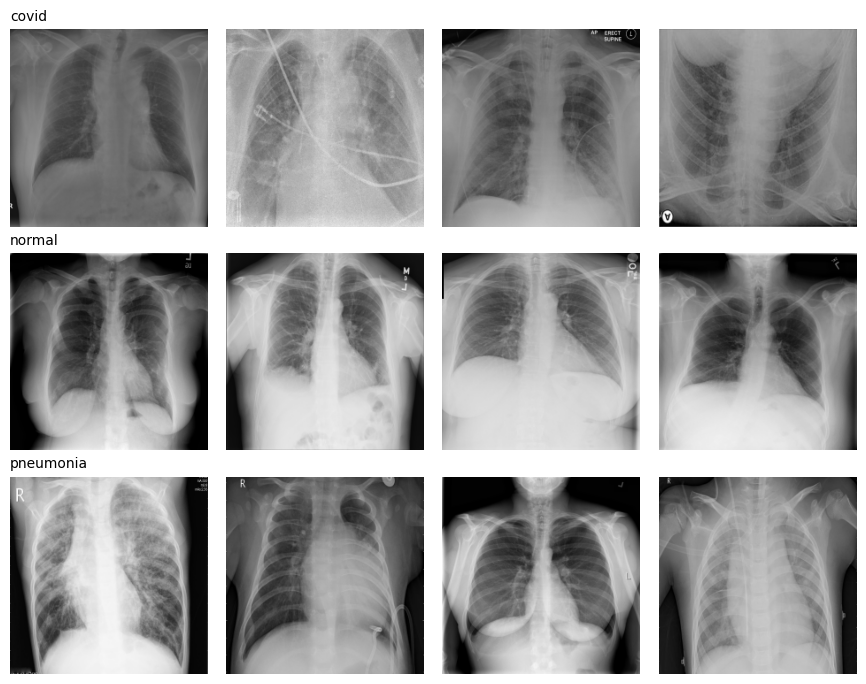

In [ ]:
# Loads all images into memory at 224 by 224 pixels and shows a few examples.
t0 = time.time()
images = data.load_images(paths, CONFIG["image_size"])
print(f"Loaded {len(images)} images in {time.time() - t0:.0f} seconds, array shape {images.shape}.")
evaluate.show_samples(images, labels, CLASSES)

In [ ]:
# Assigns every image to a collection from its file type and original size.
props = data.file_properties(paths)
coll = data.collections(props)
display(data.collection_table(coll, labels, CLASSES))

# Groups used by the source balanced weights: normal and pneumonia are split by collection, covid stays one group.
weight_groups = np.array([CLASSES[l] if CLASSES[l] == "covid" else f"{CLASSES[l]}, {c}" for l, c in zip(labels, coll)])
strata = np.array([f"{CLASSES[l]}, {c}" for l, c in zip(labels, coll)])

class,covid,normal,pneumonia
collection,,,
PNG collection,2,1977,176
JPEG collection,181,336,2137
other files,2130,0,0
total,2313,2313,2313


## 4. Train, test, and unseen split

In [ ]:
# Joins near copies and images of the same patient into groups, so that no group is split across sets.
groups, has_near_copy, patient_key = data.make_groups(paths, images)
display(data.group_table(groups, has_near_copy, patient_key, labels, CLASSES))
print("Groups:", groups.max() + 1, "| largest group:", np.bincount(groups).max(), "images")

Near copy bar 0.98: largest near copy group has 7 images.


,images,with a near copy,with a patient code in the file name,sharing a group with another image
class,,,,
covid,2313,947,0,947
normal,2313,5,2313,1402
pneumonia,2313,9,2312,1423


Groups: 4372 | largest group: 16 images


In [ ]:
# Makes the split once with a fixed seed and checks it.
sp = CONFIG["split"]
tr, te, unseen = data.three_way_split(strata, groups, sp["test"], sp["unseen"], CONFIG["split_seed"])
assert len(set(tr) & set(te)) == 0 and len(set(tr) & set(unseen)) == 0 and len(set(te) & set(unseen)) == 0
assert len(tr) + len(te) + len(unseen) == len(labels)
side = np.zeros(len(labels), int); side[te] = 1; side[unseen] = 2
assert pd.Series(side).groupby(groups).nunique().max() == 1, "A group was split across sets."
display(data.split_table((tr, te, unseen), labels, coll, CLASSES))
pd.DataFrame({"file": [os.path.relpath(p, DATASET) for p in paths],
              "set": np.array(["train", "test", "unseen"])[side]}).to_csv("/content/week11_split.csv", index=False)
print("Split saved to /content/week11_split.csv. The unseen images are not used again until Section 9.")

,images,share,"covid, PNG collection","covid, JPEG collection","covid, other files","normal, PNG collection","normal, JPEG collection","pneumonia, PNG collection","pneumonia, JPEG collection"
set,,,,,,,,,
train,4857,70.0%,1,136,1482,1384,236,123,1495
test,1041,15.0%,0,24,323,297,50,26,321
unseen,1041,15.0%,1,21,325,296,50,27,321


Split saved to /content/week11_split.csv. The unseen images are not used again until Section 9.


## 5. Parent paper 2: lung outlines

`lung_focus.py` downloads the released model definition (`StackedNet.py`) and trained weights (`SegmentationDNN.pt`) of the second parent paper, checks both files against fixed SHA256 fingerprints, and produces a lung map for every image. The maps are used in three ways: to build the lungs only input of the second parent paper, to guide the classifier during training, and to measure where the classifier looks.

/content/pyimagesearch-covid19-image-classification
[INFO] device: cuda
[INFO] 6939 images in 3 classes: ['covid', 'normal', 'pneumonia']
[INFO] downloading StackedNet.py ...
[INFO] StackedNet.py verified
[INFO] downloading SegmentationDNN.pt ...
[INFO] SegmentationDNN.pt verified
[INFO] lung finder: 96/6939 images, 39.9 images per second, about 2.9 minutes left
[INFO] lung finder: 640/6939 images, 74.1 images per second, about 1.4 minutes left
[INFO] lung finder: 1280/6939 images, 80.0 images per second, about 1.2 minutes left
[INFO] lung finder: 1920/6939 images, 82.0 images per second, about 1.0 minutes left
[INFO] lung finder: 2560/6939 images, 82.9 images per second, about 0.9 minutes left
[INFO] lung finder: 3200/6939 images, 83.3 images per second, about 0.7 minutes left
[INFO] lung finder: 3840/6939 images, 83.6 images per second, about 0.6 minutes left
[INFO] lung finder: 4480/6939 images, 83.6 images per second, about 0.5 minutes left
[INFO] lung finder: 5120/6939 images, 83.

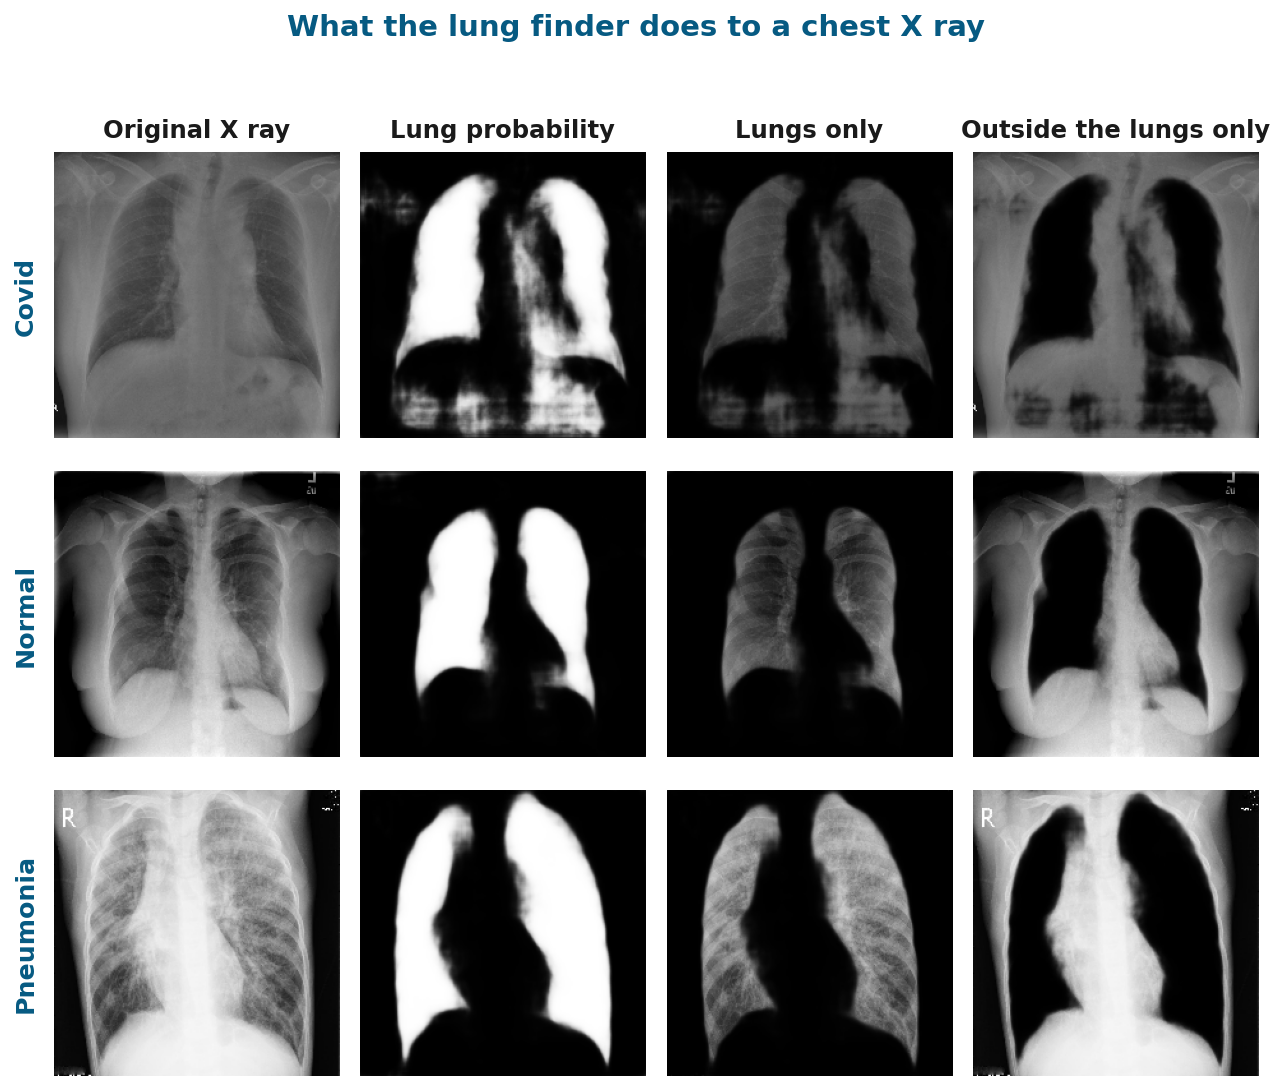

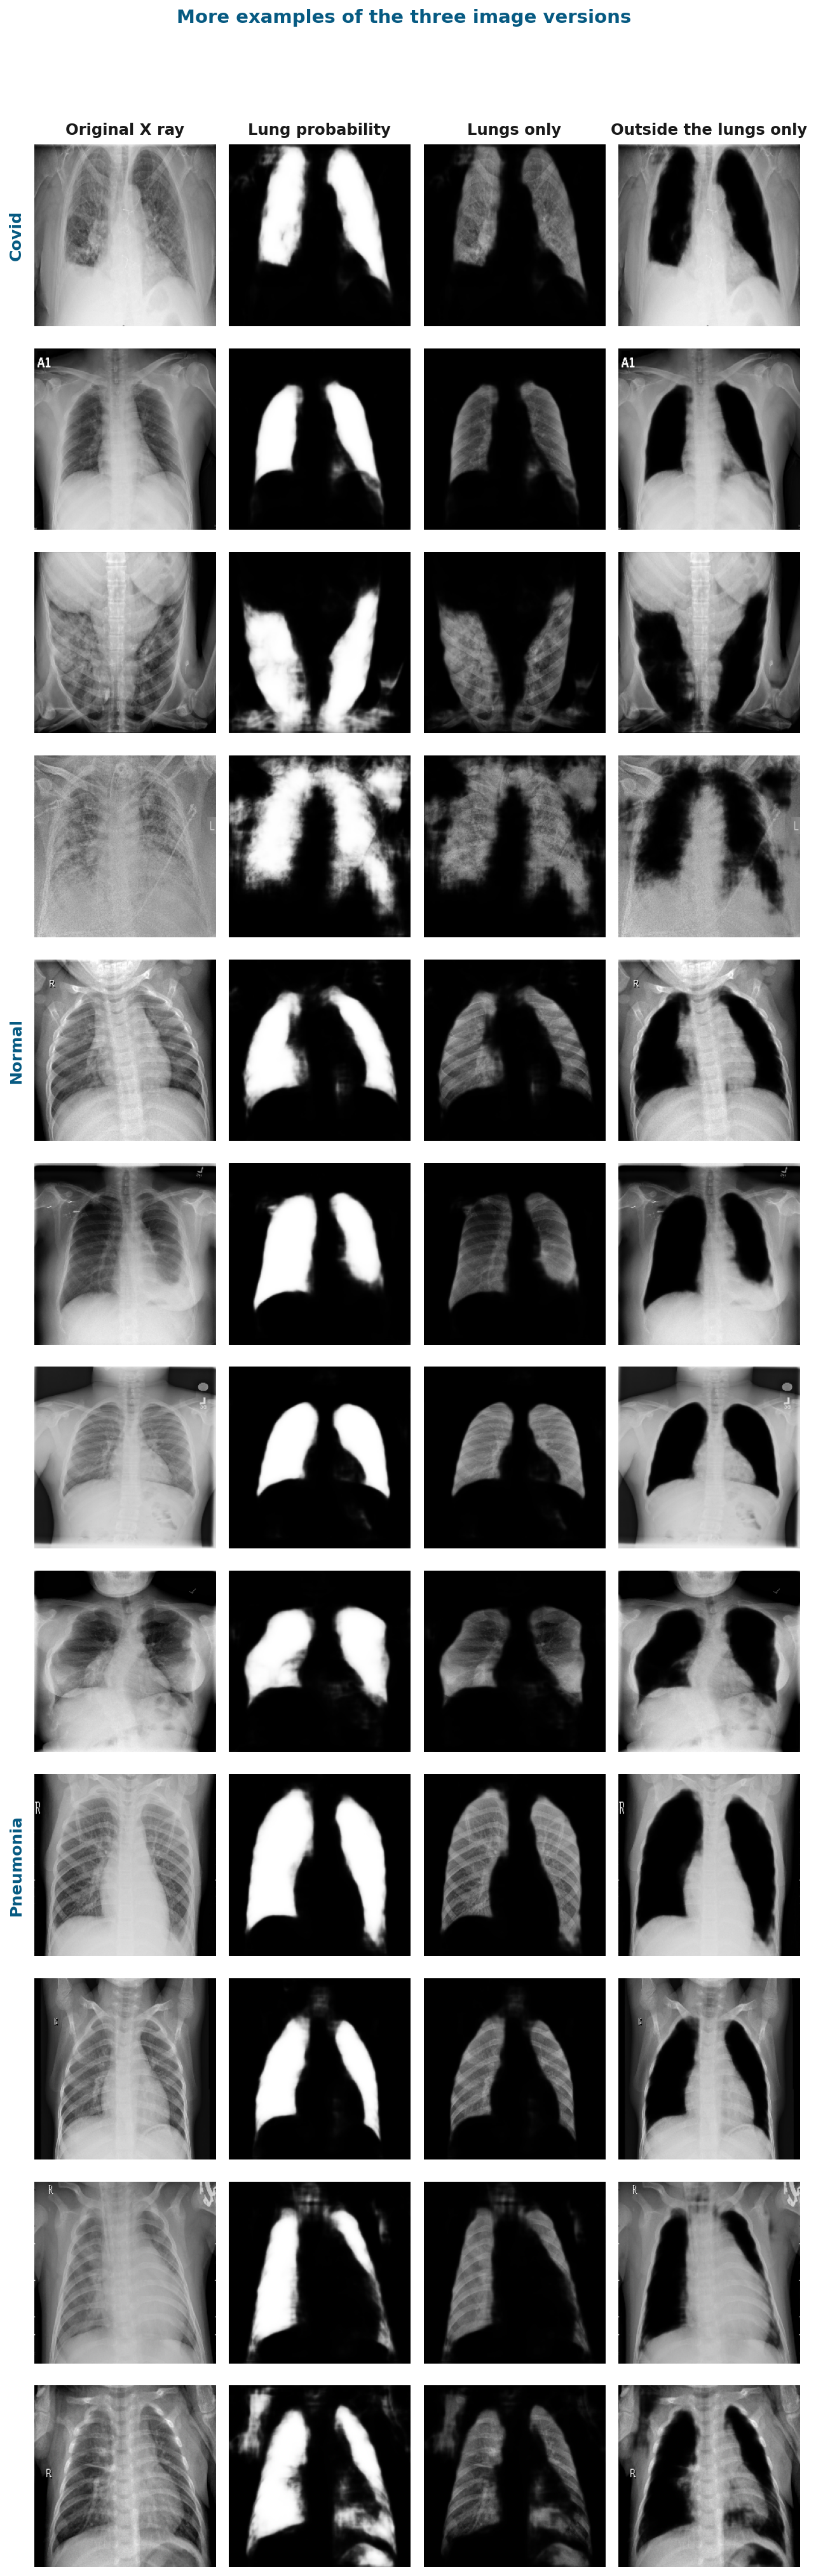

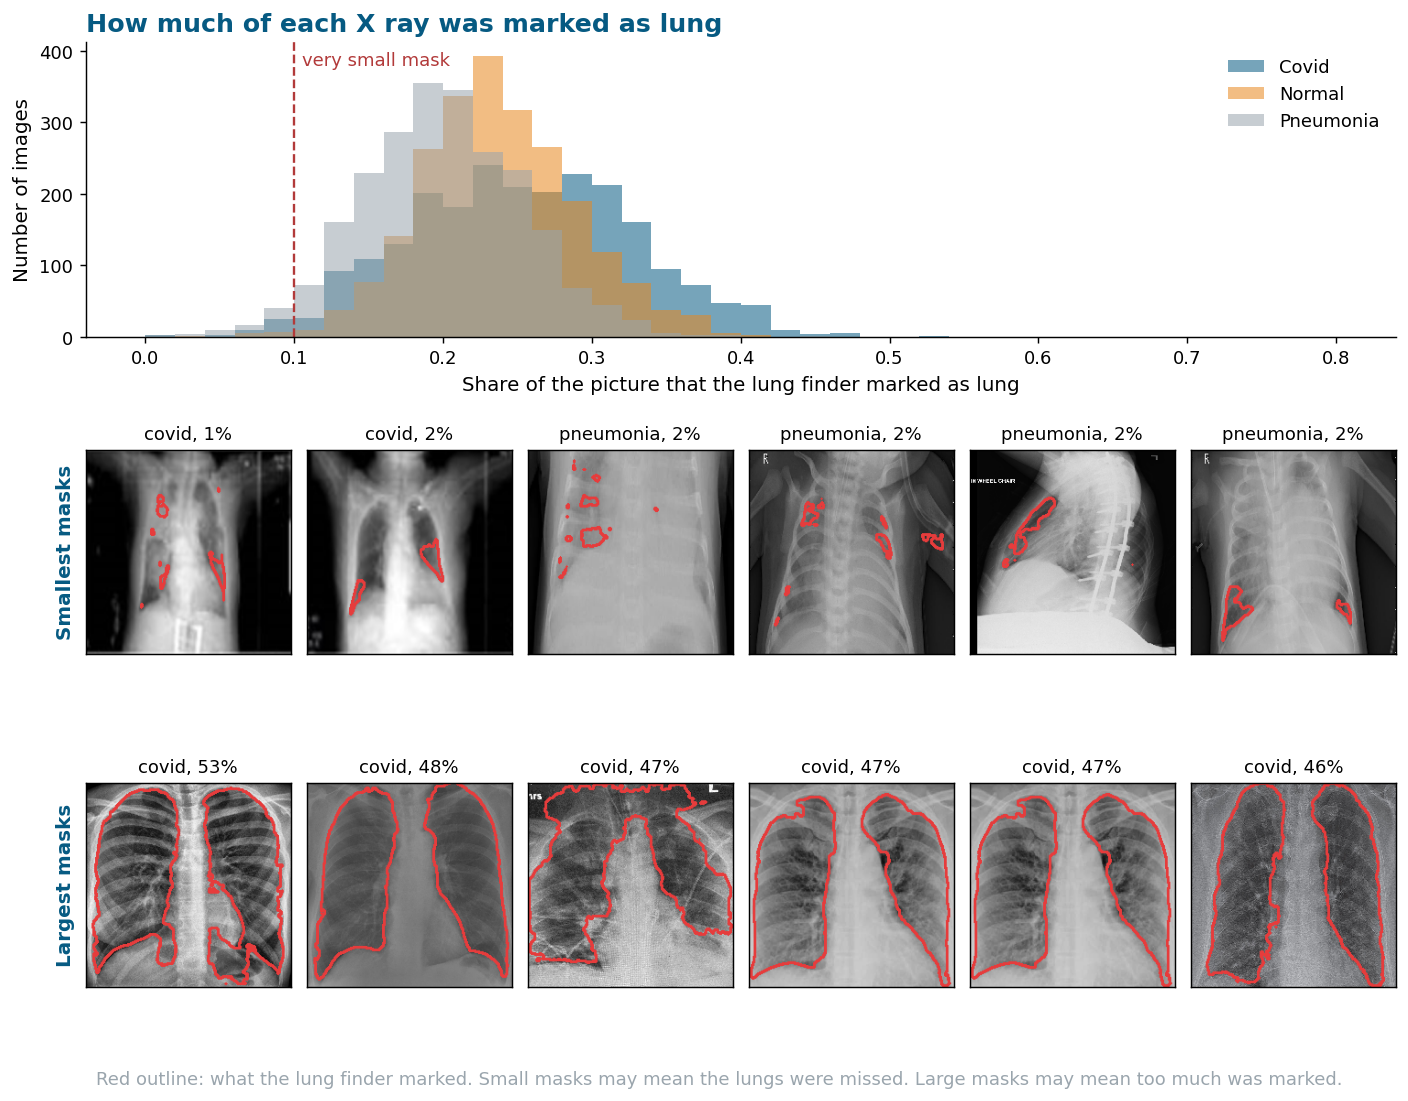

In [ ]:
LUNG_DIR = "/content/lung_data"
%cd {REPO}
!python lung_focus.py --dataset {DATASET} --outdir {LUNG_DIR}
%cd /content
assert os.path.exists(f"{LUNG_DIR}/masks.npz"), "The lung finder did not finish. Read the messages printed above."
for name in ["lung_focus_preview.png", "lung_focus_more.png", "lung_focus_quality.png"]:
    if os.path.exists(f"{LUNG_DIR}/{name}"):
        display(Image(f"{LUNG_DIR}/{name}"))

On average, the lungs cover 23% of the picture.


lung share of picture (%)
class     collection                                
covid     JPEG collection                       26.3
          PNG collection                        31.6
          other files                           25.5
normal    JPEG collection                       21.2
          PNG collection                        24.4
pneumonia JPEG collection                       20.2
          PNG collection                        22.6

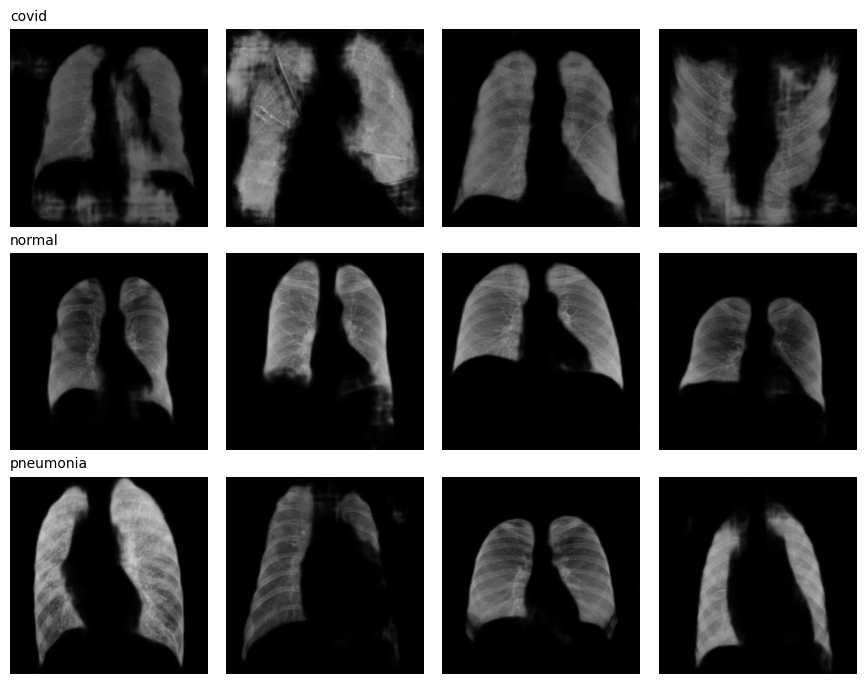

In [ ]:
# Lung maps in the same order as the images, the lungs only images, and the lung share of each cell of a 7 by 7 grid.
masks = lungs.load_masks(f"{LUNG_DIR}/masks.npz", DATASET, paths)
images_lungs = lungs.lungs_only(images, masks)
LUNG_GRID = lungs.lung_grid(masks, 7)
LUNG_AREA = float(LUNG_GRID.mean())
print(f"On average, the lungs cover {LUNG_AREA:.0%} of the picture.")
area = pd.DataFrame({"class": [CLASSES[l] for l in labels], "collection": coll, "lung share": LUNG_GRID.mean((1, 2)).astype(float)})
display((area.groupby(["class", "collection"])["lung share"].mean() * 100).round(1).to_frame("lung share of picture (%)"))
evaluate.show_samples(images_lungs, labels, CLASSES)

## 6. Feature grids from the frozen networks

In [ ]:
# Each network reads every image once. The output of its last layer is kept as a 7 by 7 grid, for the full image and for the lungs only image.
MAPS = {}
t0 = time.time()
for name in CONFIG["backbones"]:
    MAPS[name] = models.extract_feature_maps(name, images, CONFIG["image_size"], CONFIG["weights"])
    MAPS[name + ", lungs only"] = models.extract_feature_maps(name, images_lungs, CONFIG["image_size"], CONFIG["weights"])
    print(f"{name}: grid {MAPS[name].shape[1:]}, {time.time() - t0:.0f} seconds so far")
    assert MAPS[name].shape[1] == LUNG_GRID.shape[1], "The feature grid and the lung grid differ in size."
del images_lungs
POOLED = {k: v.astype(np.float32).mean((1, 2)) for k, v in MAPS.items()}

80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step
VGG19: grid (7, 7, 512), 167 seconds so far
74836368/74836368 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
DenseNet201: grid (7, 7, 1920), 556 seconds so far


## 7. References on the train and test sets

* **File properties only:** a decision tree that reads the file type, original width and height, color mode, and file size, and never sees the picture.
* **Week 10 classifier:** the classifier from the Week 10 notebook (average pooled features, Dense 64, Dropout 0.5).
* **Lungs only input:** the approach of the second parent paper, with everything outside the lungs blacked out before the network reads the image.
* **Baseline:** the grid classifier trained in the plain way. This is the starting point that the modified block changes.

In [ ]:
RESULTS = {"test": [], "unseen": []}     # one row per model and seed
PROBS = {"test": {}, "unseen": {}}       # probabilities per (backbone, model, seed)
MODELS = {}


def evaluate_on(split_name, idx, backbone, model_name, seed, model, kind, maps_key):
    if kind == "grid":
        p, ev, cam = train.predict_grid_head(model, MAPS[maps_key], idx, LUNG_GRID)
    else:
        p, ev, cam = model.predict(POOLED[maps_key][idx], verbose=0), None, None
    row = {"backbone": backbone, "model": model_name, "seed": seed}
    row.update(evaluate.set_metrics(labels[idx], p, coll[idx], CLASSES, ev, cam))
    RESULTS[split_name].append(row)
    PROBS[split_name][(backbone, model_name, seed)] = p
    return row


def run(backbone, model_name, seed, kind="grid", maps_key=None, lam=0.0, weights=None):
    maps_key = maps_key or backbone
    t0 = time.time()
    if kind == "grid":
        model, hist = train.fit_grid_head(MAPS[maps_key], labels, tr, LUNG_GRID, N_CLASSES, lam=lam, sample_weight=weights,
                                          epochs=CONFIG["epochs"], batch=CONFIG["batch"], seed=seed)
    else:
        model, hist = train.fit_pooled_head(POOLED[maps_key], labels, tr, N_CLASSES, epochs=CONFIG["epochs"],
                                            batch=CONFIG["batch"], seed=seed), None
    MODELS[(backbone, model_name, seed)] = (model, kind, maps_key, hist)
    row = evaluate_on("test", te, backbone, model_name, seed, model, kind, maps_key)
    print(f"{backbone} | {model_name} | seed {seed}: test accuracy {row['accuracy']:.1%}, "
          f"PNG pneumonia recall {row['pneumonia recall, PNG']:.1%}, {time.time() - t0:.0f} s")
    return row

In [ ]:
# File properties only, trained on the train set and scored on the test set.
prop_feats = data.encode_properties(props)
tree = train.fit_tree(prop_feats, labels, tr, seed=0)
p_tree = tree.predict_proba(prop_feats[te])
row = {"backbone": "none", "model": "file properties only", "seed": 0}
row.update(evaluate.set_metrics(labels[te], p_tree, coll[te], CLASSES))
RESULTS["test"].append(row)
PROBS["test"][("none", "file properties only", 0)] = p_tree
display(pd.DataFrame([row]).set_index("model").drop(columns=["backbone", "seed"]).round(3))

,accuracy,macro F1,macro AUC,covid recall,"pneumonia recall, PNG","normal recall, PNG","normal vs pneumonia AUC, PNG","pneumonia recall, JPEG","normal recall, JPEG","normal vs pneumonia AUC, JPEG"
model,,,,,,,,,,
file properties only,0.968,0.968,0.984,0.983,0.0,1.0,0.498,0.997,1.0,0.999


In [ ]:
# Week 10 classifier, lungs only input, and the baseline, three seeds each.
for name in CONFIG["backbones"]:
    for s in CONFIG["seeds"]:
        run(name, "Week 10 classifier", s, kind="pooled")
        run(name, "lungs only input (parent paper 2)", s, maps_key=name + ", lungs only")
        run(name, "baseline", s)

VGG19 | Week 10 classifier | seed 0: test accuracy 95.3%, PNG pneumonia recall 3.8%, 13 s
VGG19 | lungs only input (parent paper 2) | seed 0: test accuracy 87.9%, PNG pneumonia recall 7.7%, 19 s
VGG19 | baseline | seed 0: test accuracy 95.0%, PNG pneumonia recall 7.7%, 14 s
VGG19 | Week 10 classifier | seed 1: test accuracy 94.8%, PNG pneumonia recall 3.8%, 11 s
VGG19 | lungs only input (parent paper 2) | seed 1: test accuracy 89.9%, PNG pneumonia recall 3.8%, 15 s
VGG19 | baseline | seed 1: test accuracy 93.4%, PNG pneumonia recall 0.0%, 15 s
VGG19 | Week 10 classifier | seed 2: test accuracy 94.7%, PNG pneumonia recall 3.8%, 10 s
VGG19 | lungs only input (parent paper 2) | seed 2: test accuracy 90.3%, PNG pneumonia recall 11.5%, 14 s
VGG19 | baseline | seed 2: test accuracy 95.9%, PNG pneumonia recall 3.8%, 15 s
DenseNet201 | Week 10 classifier | seed 0: test accuracy 95.5%, PNG pneumonia recall 15.4%, 11 s
DenseNet201 | lungs only input (parent paper 2) | seed 0: test accuracy 89.3%

## 8. The modified training block

### 8a. Source balanced weights
Weight per training image for each group. Each class holds one third of the total weight, and inside normal and pneumonia each collection holds half of its class's weight.

In [ ]:
W_TRAIN = train.source_weights(labels, weight_groups, tr)
display(train.weight_table(labels, weight_groups, tr, W_TRAIN, CLASSES))

images  weight_per_image  total_weight  share_of_total_weight
class     group                                                                                    
covid     covid                         1619             1.000        1619.0                   33.3
normal    normal, JPEG collection        236             3.430         809.5                   16.7
          normal, PNG collection        1384             0.585         809.5                   16.7
pneumonia pneumonia, JPEG collection    1495             0.541         809.5                   16.7
          pneumonia, PNG collection      123             6.581         809.5                   16.7

### 8b. Choosing the penalty strength on the test set
The lung guided penalty is tried at several strengths (lambda) with separate seeds. The chosen strength is the largest one whose average test accuracy stays within 2 points of training without the penalty. The rule is fixed before the sweep is run.

VGG19, lambda 0: test accuracy 95.8%, evidence inside lungs 21.5%
VGG19, lambda 0.5: test accuracy 93.4%, evidence inside lungs 52.2%
VGG19, lambda 1: test accuracy 92.9%, evidence inside lungs 73.8%
VGG19, lambda 2: test accuracy 91.9%, evidence inside lungs 82.6%
VGG19, lambda 5: test accuracy 89.7%, evidence inside lungs 87.3%
VGG19, lambda 10: test accuracy 87.6%, evidence inside lungs 88.9%
DenseNet201, lambda 0: test accuracy 94.6%, evidence inside lungs 26.1%
DenseNet201, lambda 0.5: test accuracy 94.1%, evidence inside lungs 60.2%
DenseNet201, lambda 1: test accuracy 94.1%, evidence inside lungs 76.6%
DenseNet201, lambda 2: test accuracy 93.4%, evidence inside lungs 83.4%
DenseNet201, lambda 5: test accuracy 93.0%, evidence inside lungs 84.9%
DenseNet201, lambda 10: test accuracy 78.1%, evidence inside lungs 87.6%


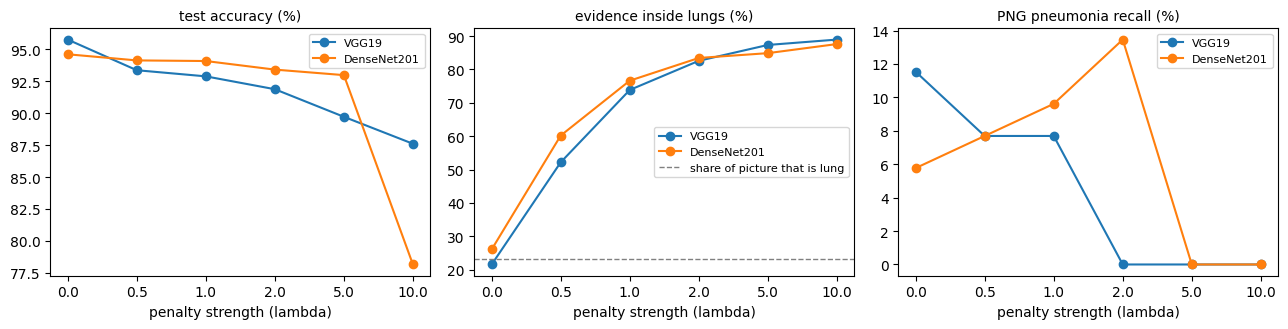

accuracy  pneumonia recall, PNG  normal vs pneumonia AUC, PNG  evidence inside lungs  Grad CAM heat inside lungs
backbone    lambda                                                                                                                  
DenseNet201 0.0        0.946                  0.058                         0.710                  0.261                       0.273
            0.5        0.941                  0.077                         0.666                  0.602                       0.577
            1.0        0.941                  0.096                         0.618                  0.766                       0.723
            2.0        0.934                  0.135                         0.581                  0.834                       0.794
            5.0        0.930                  0.000                         0.513                  0.849                       0.834
            10.0       0.781                  0.000                         0.414                  0.876                       0.851
VGG19       0.0        0.958                  0.115                         0.653                  0.215                       0.217
            0.5        0.934                  0.077                         0.554                  0.522                       0.503
            1.0        0.929                  0.077                         0.522                  0.738                       0.681
            2.0        0.919                  0.000                         0.529                  0.826                       0.770
            5.0        0.897                  0.000                         0.484                  0.873                       0.844
            10.0       0.876                  0.000                         0.470                  0.889                       0.870

Chosen penalty strength: {'VGG19': 0.5, 'DenseNet201': 5.0}


In [ ]:
sweep = []
for name in CONFIG["backbones"]:
    for lam in CONFIG["lambdas"]:
        for s in CONFIG["sweep_seeds"]:
            model, _ = train.fit_grid_head(MAPS[name], labels, tr, LUNG_GRID, N_CLASSES, lam=lam,
                                           epochs=CONFIG["epochs"], batch=CONFIG["batch"], seed=s)
            p, ev, cam = train.predict_grid_head(model, MAPS[name], te, LUNG_GRID)
            r = {"backbone": name, "lambda": lam, "seed": s}
            r.update(evaluate.set_metrics(labels[te], p, coll[te], CLASSES, ev, cam))
            sweep.append(r)
        g = pd.DataFrame(sweep).query("backbone == @name and `lambda` == @lam")
        print(f"{name}, lambda {lam}: test accuracy {g['accuracy'].mean():.1%}, evidence inside lungs {g['evidence inside lungs'].mean():.1%}")
sweep = pd.DataFrame(sweep)
evaluate.plot_sweep(sweep, LUNG_AREA)

CHOSEN_LAMBDA = {}
for name in CONFIG["backbones"]:
    g = sweep[sweep.backbone == name].groupby("lambda")["accuracy"].mean()
    ok = [lam for lam in g.index if lam > 0 and g[lam] >= g[0] - CONFIG["max_accuracy_drop"]]
    CHOSEN_LAMBDA[name] = max(ok) if ok else min(l for l in g.index if l > 0)
cols = ["accuracy", "pneumonia recall, PNG", "normal vs pneumonia AUC, PNG", "evidence inside lungs", "Grad CAM heat inside lungs"]
display(sweep.groupby(["backbone", "lambda"])[cols].mean().round(3))
print("Chosen penalty strength:", CHOSEN_LAMBDA)

### 8c. The four versions on the test set

In [ ]:
for name in CONFIG["backbones"]:
    lam = CHOSEN_LAMBDA[name]
    for s in CONFIG["seeds"]:
        run(name, "source weights", s, weights=W_TRAIN)
        run(name, "lung guided", s, lam=lam)
        run(name, "lung guided + source weights", s, lam=lam, weights=W_TRAIN)

VGG19 | source weights | seed 0: test accuracy 93.5%, PNG pneumonia recall 30.8%, 14 s
VGG19 | lung guided | seed 0: test accuracy 93.2%, PNG pneumonia recall 7.7%, 14 s
VGG19 | lung guided + source weights | seed 0: test accuracy 91.5%, PNG pneumonia recall 26.9%, 15 s
VGG19 | source weights | seed 1: test accuracy 94.2%, PNG pneumonia recall 15.4%, 14 s
VGG19 | lung guided | seed 1: test accuracy 92.9%, PNG pneumonia recall 3.8%, 15 s
VGG19 | lung guided + source weights | seed 1: test accuracy 92.5%, PNG pneumonia recall 15.4%, 15 s
VGG19 | source weights | seed 2: test accuracy 95.1%, PNG pneumonia recall 19.2%, 15 s
VGG19 | lung guided | seed 2: test accuracy 94.4%, PNG pneumonia recall 3.8%, 14 s
VGG19 | lung guided + source weights | seed 2: test accuracy 92.8%, PNG pneumonia recall 15.4%, 15 s
DenseNet201 | source weights | seed 0: test accuracy 94.3%, PNG pneumonia recall 19.2%, 27 s
DenseNet201 | lung guided | seed 0: test accuracy 92.3%, PNG pneumonia recall 0.0%, 26 s
Dense

In [ ]:
ORDER = ["Week 10 classifier", "lungs only input (parent paper 2)", "baseline", "source weights", "lung guided", "lung guided + source weights"]
SHOW = ["accuracy", "macro AUC", "covid recall", "pneumonia recall, PNG", "normal recall, PNG", "pneumonia recall, JPEG",
        "normal recall, JPEG", "normal vs pneumonia AUC, PNG", "normal vs pneumonia AUC, JPEG", "evidence inside lungs", "Grad CAM heat inside lungs"]


def results_table(split_name, backbone):
    df = pd.DataFrame(RESULTS[split_name])
    t = evaluate.summarize(df[df.backbone == backbone].drop(columns="backbone").to_dict("records"), order=ORDER)
    return t[[c for c in SHOW if c in t.columns]]


print("Test set, file properties only:")
display(pd.DataFrame([r for r in RESULTS["test"] if r["model"] == "file properties only"]).set_index("model")[SHOW[:9]].round(3))
for name in CONFIG["backbones"]:
    print(f"Test set, {name} (mean ± standard deviation over {len(CONFIG['seeds'])} seeds). Lungs cover {LUNG_AREA:.0%} of the picture.")
    display(results_table("test", name))

Test set, file properties only:


,accuracy,macro AUC,covid recall,"pneumonia recall, PNG","normal recall, PNG","pneumonia recall, JPEG","normal recall, JPEG","normal vs pneumonia AUC, PNG","normal vs pneumonia AUC, JPEG"
model,,,,,,,,,
file properties only,0.968,0.984,0.983,0.0,1.0,0.997,1.0,0.498,0.999


Test set, VGG19 (mean ± standard deviation over 3 seeds). Lungs cover 23% of the picture.


,accuracy,macro AUC,covid recall,"pneumonia recall, PNG","normal recall, PNG","pneumonia recall, JPEG","normal recall, JPEG","normal vs pneumonia AUC, PNG","normal vs pneumonia AUC, JPEG",evidence inside lungs,Grad CAM heat inside lungs
Week 10 classifier,94.9 ± 0.3,0.989 ± 0.001,95.0 ± 1.6,3.8 ± 0.0,97.9 ± 1.2,99.5 ± 0.4,95.3 ± 1.2,0.699 ± 0.017,0.999 ± 0.001,nan ± nan,nan ± nan
lungs only input (parent paper 2),89.4 ± 1.3,0.972 ± 0.000,90.6 ± 0.3,7.7 ± 3.8,90.7 ± 3.3,96.3 ± 0.9,71.3 ± 14.2,0.690 ± 0.014,0.972 ± 0.003,35.8 ± 0.8,40.6 ± 1.3
baseline,94.7 ± 1.3,0.989 ± 0.001,94.9 ± 3.8,3.8 ± 3.8,97.9 ± 2.0,99.2 ± 1.2,94.0 ± 4.0,0.691 ± 0.038,0.999 ± 0.000,21.7 ± 0.7,23.3 ± 0.1
source weights,94.3 ± 0.8,0.988 ± 0.001,95.4 ± 2.7,21.8 ± 8.0,93.9 ± 0.7,99.1 ± 0.5,95.3 ± 3.1,0.694 ± 0.028,0.998 ± 0.001,21.4 ± 0.6,23.2 ± 0.6
lung guided,93.5 ± 0.8,0.983 ± 0.001,94.1 ± 0.4,5.1 ± 2.2,94.7 ± 2.5,99.2 ± 0.4,91.3 ± 4.2,0.560 ± 0.024,0.998 ± 0.001,54.4 ± 0.1,56.7 ± 2.9
lung guided + source weights,92.3 ± 0.7,0.985 ± 0.001,92.7 ± 1.6,19.2 ± 6.7,91.6 ± 2.0,97.8 ± 1.4,96.0 ± 3.5,0.662 ± 0.015,0.998 ± 0.000,44.1 ± 0.5,45.6 ± 2.4


Test set, DenseNet201 (mean ± standard deviation over 3 seeds). Lungs cover 23% of the picture.


,accuracy,macro AUC,covid recall,"pneumonia recall, PNG","normal recall, PNG","pneumonia recall, JPEG","normal recall, JPEG","normal vs pneumonia AUC, PNG","normal vs pneumonia AUC, JPEG",evidence inside lungs,Grad CAM heat inside lungs
Week 10 classifier,95.3 ± 0.5,0.989 ± 0.000,96.7 ± 0.7,6.4 ± 8.0,97.9 ± 1.4,98.2 ± 1.6,97.3 ± 4.6,0.695 ± 0.019,0.999 ± 0.000,nan ± nan,nan ± nan
lungs only input (parent paper 2),90.0 ± 0.6,0.974 ± 0.002,91.6 ± 1.4,6.4 ± 5.9,92.4 ± 4.4,94.9 ± 3.5,76.0 ± 13.1,0.612 ± 0.034,0.975 ± 0.001,33.0 ± 0.7,35.8 ± 0.6
baseline,94.5 ± 0.8,0.989 ± 0.000,96.2 ± 0.7,15.4 ± 3.8,94.7 ± 3.1,99.3 ± 0.4,92.0 ± 2.0,0.703 ± 0.006,0.998 ± 0.000,26.0 ± 0.3,27.5 ± 0.1
source weights,93.9 ± 1.5,0.989 ± 0.000,96.2 ± 1.2,20.5 ± 5.9,92.4 ± 6.9,98.8 ± 0.5,94.7 ± 4.2,0.713 ± 0.016,0.999 ± 0.000,26.0 ± 0.2,27.5 ± 0.2
lung guided,92.0 ± 1.3,0.967 ± 0.004,92.8 ± 0.9,0.0 ± 0.0,96.4 ± 0.8,98.7 ± 0.6,66.0 ± 20.0,0.524 ± 0.009,0.960 ± 0.019,85.2 ± 1.1,84.4 ± 0.6
lung guided + source weights,83.8 ± 1.5,0.931 ± 0.020,91.5 ± 1.5,21.8 ± 5.9,74.7 ± 6.4,86.5 ± 8.0,98.7 ± 1.2,0.558 ± 0.045,0.993 ± 0.001,83.5 ± 3.4,80.3 ± 4.5


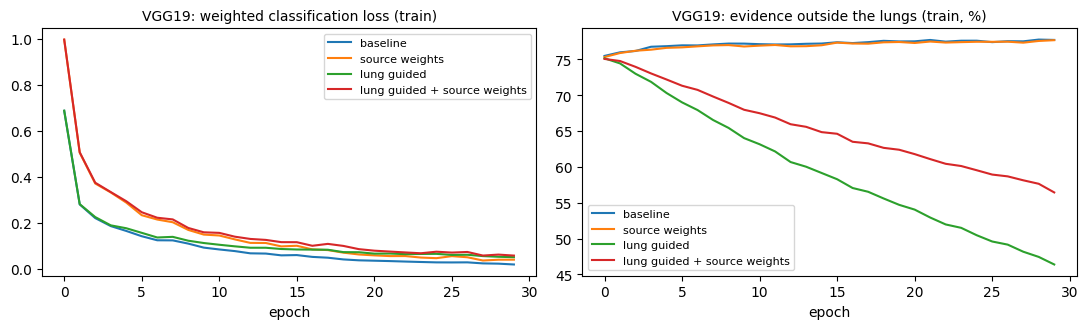

In [ ]:
# Training curves of one run per version: classification loss and the share of evidence outside the lungs.
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for model_name in ["baseline", "source weights", "lung guided", "lung guided + source weights"]:
    hist = MODELS[(CONFIG["backbones"][0], model_name, CONFIG["seeds"][0])][3]
    axes[0].plot(hist["loss"], label=model_name)
    axes[1].plot(np.array(hist["outside_share"]) * 100, label=model_name)
axes[0].set_title(f"{CONFIG['backbones'][0]}: weighted classification loss (train)", fontsize=10)
axes[1].set_title(f"{CONFIG['backbones'][0]}: evidence outside the lungs (train, %)", fontsize=10)
for ax in axes:
    ax.set_xlabel("epoch")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

VGG19


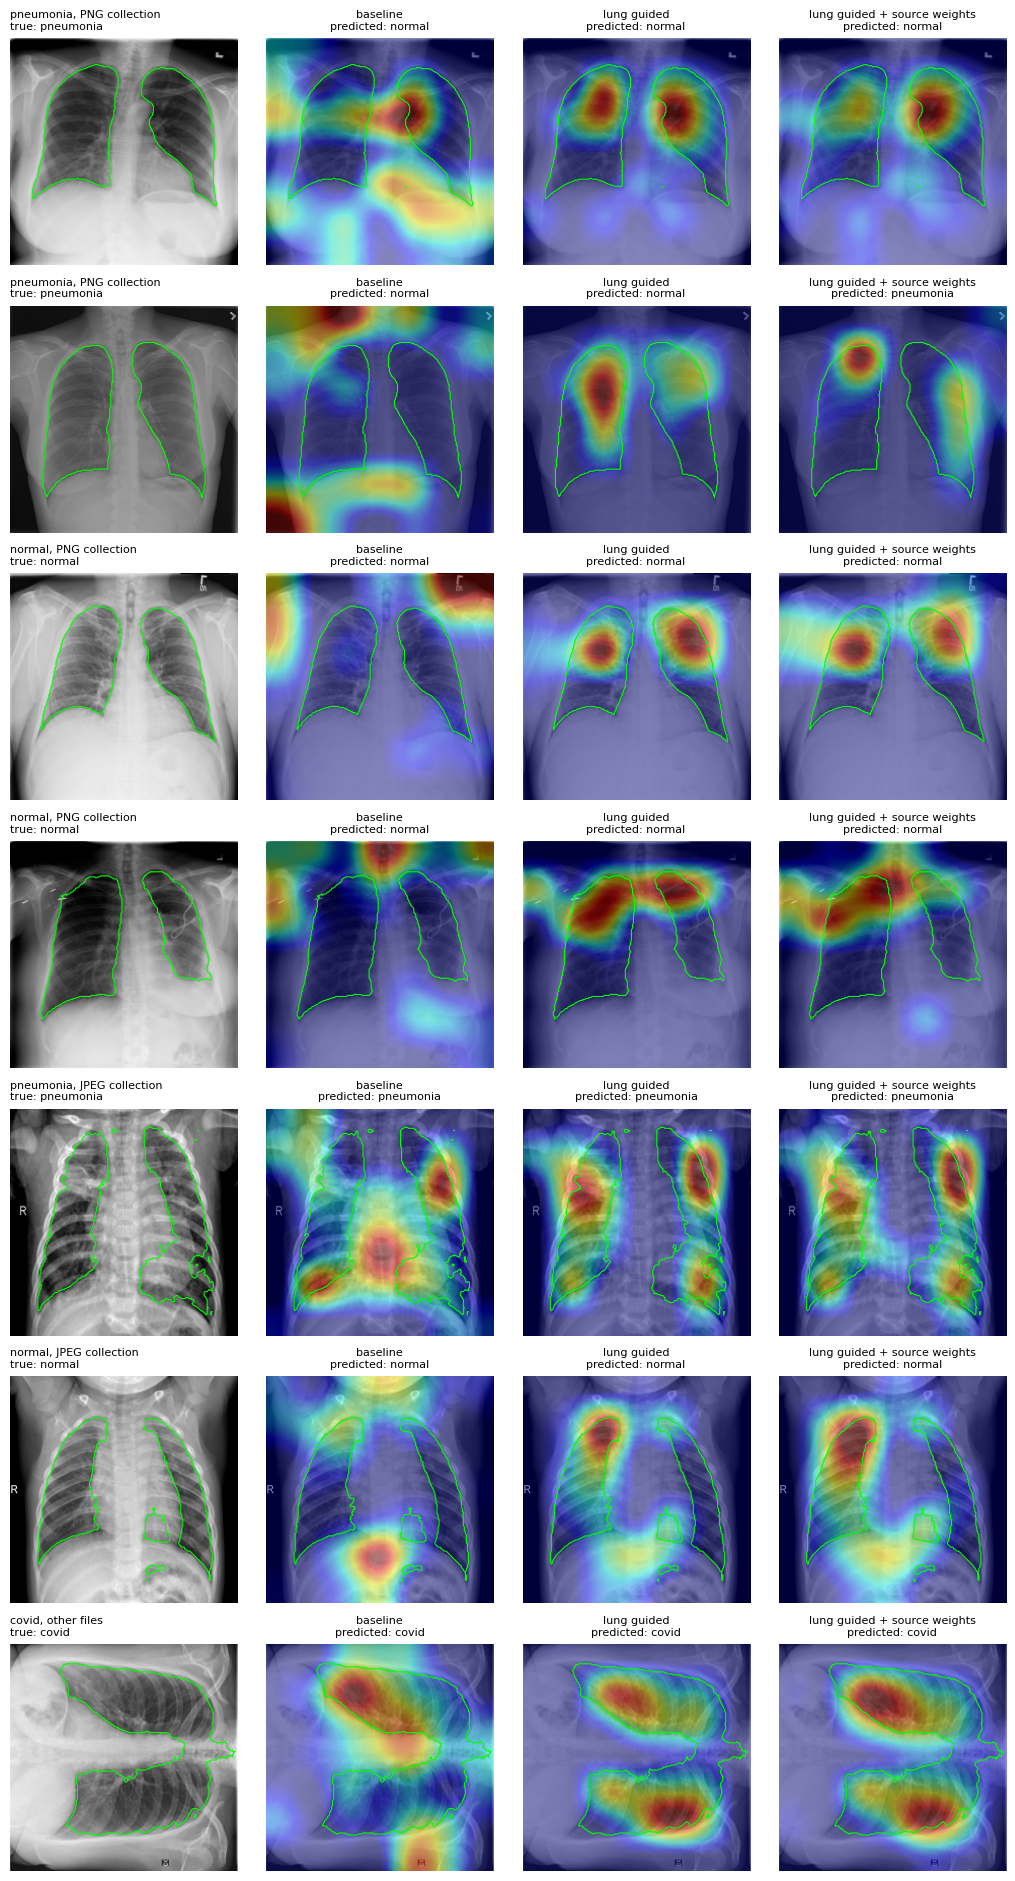

DenseNet201


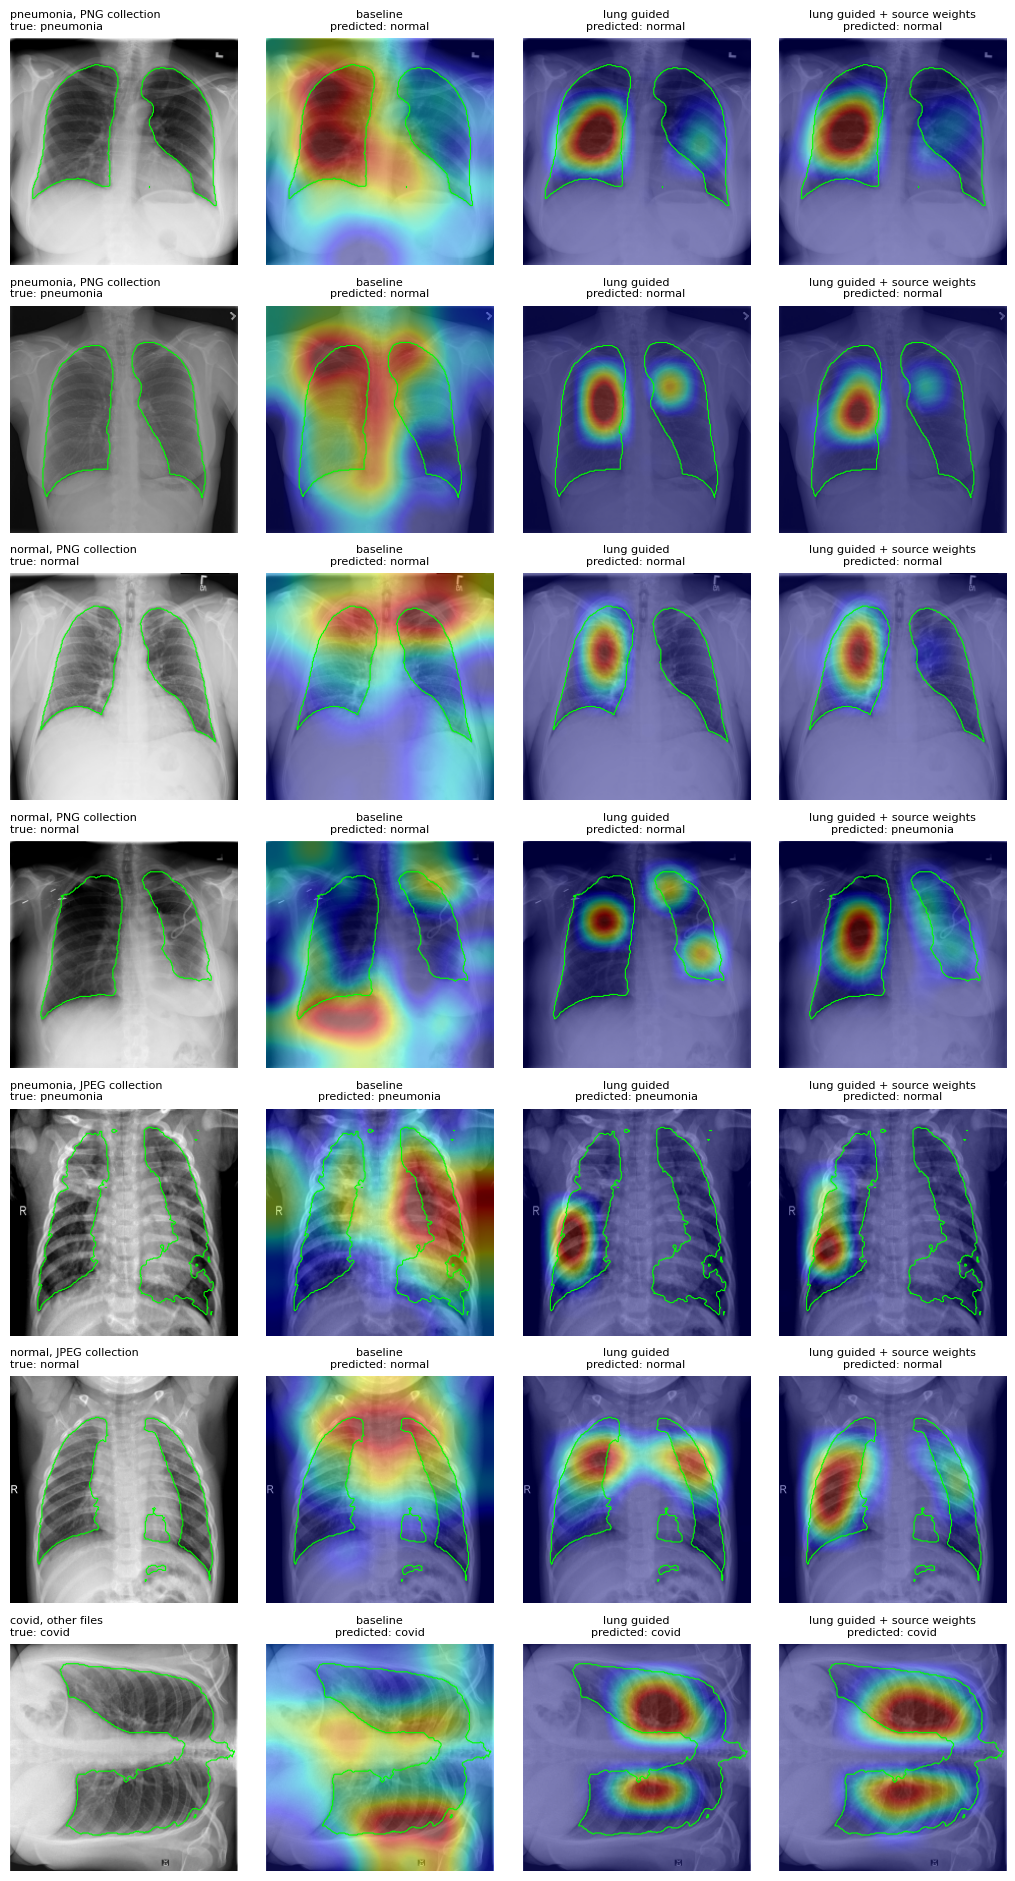

In [ ]:
# Grad CAM heat on test images for the baseline and the modified versions (first seed). The green line is the lung outline.
rng = np.random.RandomState(0)
pick, titles = [], []
for cls, col, k in [("pneumonia", "PNG collection", 2), ("normal", "PNG collection", 2), ("pneumonia", "JPEG collection", 1), ("normal", "JPEG collection", 1), ("covid", None, 1)]:
    cand = [i for i in te if CLASSES[labels[i]] == cls and (col is None or coll[i] == col)]
    for i in rng.choice(cand, min(k, len(cand)), replace=False):
        pick.append(i)
        titles.append(f"{cls}, {coll[i]}")
pick = np.array(pick)
for name in CONFIG["backbones"]:
    cams, probs = {}, {}
    for model_name in ["baseline", "lung guided", "lung guided + source weights"]:
        model = MODELS[(name, model_name, CONFIG["seeds"][0])][0]
        cams[model_name], probs[model_name] = train.gradcam_maps(model, MAPS[name], pick)
    print(name)
    evaluate.show_heatmaps(images, masks, pick, cams, probs, labels, CLASSES, titles)

## 9. Unseen set

This is the first and only time the unseen images are used. Every model trained above is scored once, with no further changes.

In [ ]:
row = {"backbone": "none", "model": "file properties only", "seed": 0}
p_tree_unseen = tree.predict_proba(prop_feats[unseen])
row.update(evaluate.set_metrics(labels[unseen], p_tree_unseen, coll[unseen], CLASSES))
RESULTS["unseen"].append(row)
PROBS["unseen"][("none", "file properties only", 0)] = p_tree_unseen
for (backbone, model_name, seed), (model, kind, maps_key, _) in MODELS.items():
    evaluate_on("unseen", unseen, backbone, model_name, seed, model, kind, maps_key)

print("Unseen set, file properties only:")
display(pd.DataFrame([r for r in RESULTS["unseen"] if r["model"] == "file properties only"]).set_index("model")[SHOW[:9]].round(3))
for name in CONFIG["backbones"]:
    print(f"Unseen set, {name} (mean ± standard deviation over {len(CONFIG['seeds'])} seeds). Parent paper 1 reports {PARENT_ACCURACY[name]} percent accuracy for this network.")
    display(results_table("unseen", name))

Unseen set, file properties only:


,accuracy,macro AUC,covid recall,"pneumonia recall, PNG","normal recall, PNG","pneumonia recall, JPEG","normal recall, JPEG","normal vs pneumonia AUC, PNG","normal vs pneumonia AUC, JPEG"
model,,,,,,,,,
file properties only,0.959,0.98,0.977,0.0,1.0,0.981,0.96,0.502,0.988


Unseen set, VGG19 (mean ± standard deviation over 3 seeds). Parent paper 1 reports 97 percent accuracy for this network.


,accuracy,macro AUC,covid recall,"pneumonia recall, PNG","normal recall, PNG","pneumonia recall, JPEG","normal recall, JPEG","normal vs pneumonia AUC, PNG","normal vs pneumonia AUC, JPEG",evidence inside lungs,Grad CAM heat inside lungs
Week 10 classifier,93.9 ± 0.5,0.987 ± 0.001,96.1 ± 0.9,1.2 ± 2.1,97.2 ± 2.0,98.2 ± 0.6,82.7 ± 6.1,0.672 ± 0.039,0.995 ± 0.001,nan ± nan,nan ± nan
lungs only input (parent paper 2),89.8 ± 0.6,0.978 ± 0.000,92.6 ± 0.4,7.4 ± 3.7,91.2 ± 1.8,97.1 ± 2.1,60.0 ± 17.3,0.666 ± 0.021,0.976 ± 0.010,35.8 ± 0.8,40.3 ± 1.4
baseline,94.4 ± 1.1,0.987 ± 0.001,97.5 ± 0.7,9.9 ± 7.7,96.1 ± 5.1,97.4 ± 1.6,89.3 ± 10.1,0.656 ± 0.032,0.996 ± 0.000,21.7 ± 0.6,23.3 ± 0.1
source weights,92.6 ± 0.8,0.986 ± 0.001,97.6 ± 0.6,24.7 ± 5.7,88.0 ± 3.4,97.5 ± 1.2,90.7 ± 6.4,0.646 ± 0.028,0.996 ± 0.001,21.5 ± 0.4,23.1 ± 0.4
lung guided,93.1 ± 0.2,0.983 ± 0.001,96.9 ± 1.4,4.9 ± 2.1,93.8 ± 2.9,96.4 ± 1.5,88.0 ± 6.0,0.586 ± 0.040,0.990 ± 0.002,54.3 ± 0.2,56.2 ± 3.2
lung guided + source weights,92.0 ± 1.0,0.984 ± 0.002,96.3 ± 1.9,19.8 ± 15.0,88.7 ± 2.8,96.3 ± 1.6,92.7 ± 8.1,0.644 ± 0.048,0.995 ± 0.001,44.0 ± 0.5,45.1 ± 2.4


Unseen set, DenseNet201 (mean ± standard deviation over 3 seeds). Parent paper 1 reports 92 percent accuracy for this network.


,accuracy,macro AUC,covid recall,"pneumonia recall, PNG","normal recall, PNG","pneumonia recall, JPEG","normal recall, JPEG","normal vs pneumonia AUC, PNG","normal vs pneumonia AUC, JPEG",evidence inside lungs,Grad CAM heat inside lungs
Week 10 classifier,93.3 ± 0.1,0.986 ± 0.000,95.4 ± 1.0,8.6 ± 11.9,94.7 ± 1.0,96.9 ± 1.1,93.3 ± 3.1,0.697 ± 0.008,0.994 ± 0.001,nan ± nan,nan ± nan
lungs only input (parent paper 2),88.3 ± 0.7,0.975 ± 0.001,92.6 ± 1.8,8.6 ± 7.7,87.8 ± 6.4,94.4 ± 4.1,65.3 ± 19.6,0.629 ± 0.012,0.961 ± 0.004,33.1 ± 0.6,35.6 ± 0.7
baseline,93.0 ± 0.4,0.986 ± 0.001,95.6 ± 0.6,24.7 ± 2.1,91.2 ± 1.5,98.1 ± 0.3,88.7 ± 3.1,0.696 ± 0.015,0.995 ± 0.001,25.9 ± 0.2,27.5 ± 0.1
source weights,92.0 ± 0.9,0.985 ± 0.001,95.3 ± 0.7,29.6 ± 9.8,87.7 ± 4.9,97.5 ± 0.9,93.3 ± 3.1,0.693 ± 0.011,0.995 ± 0.001,25.8 ± 0.2,27.5 ± 0.1
lung guided,90.5 ± 1.1,0.967 ± 0.006,93.9 ± 2.1,1.2 ± 2.1,92.8 ± 1.0,98.0 ± 1.2,54.0 ± 17.1,0.615 ± 0.010,0.926 ± 0.027,85.5 ± 1.1,84.6 ± 0.7
lung guided + source weights,82.9 ± 1.8,0.924 ± 0.020,91.6 ± 1.3,33.3 ± 11.1,71.4 ± 5.7,85.8 ± 7.1,98.0 ± 0.0,0.562 ± 0.022,0.987 ± 0.001,83.7 ± 3.3,79.5 ± 4.0


In [ ]:
# Averages the three seeds of each model, then resamples the unseen images 1,000 times for 95 percent intervals.
KEY = ["accuracy", "pneumonia recall, PNG", "normal recall, JPEG", "normal vs pneumonia AUC, PNG"]
y_u, c_u = labels[unseen], coll[unseen]


def seed_average(backbone, model_name):
    return np.mean([PROBS["unseen"][(backbone, model_name, s)] for s in CONFIG["seeds"]], axis=0)


for name in CONFIG["backbones"]:
    rows = {}
    for model_name in ORDER:
        p = seed_average(name, model_name)
        point = evaluate.set_metrics(y_u, p, c_u, CLASSES)
        ci = evaluate.bootstrap(y_u, p, c_u, CLASSES, KEY, n=CONFIG["bootstrap"], seed=0)
        rows[model_name] = {m: f"{point[m]:.3f} [{ci[m][0]:.3f}, {ci[m][1]:.3f}]" for m in KEY}
    print(f"{name}, unseen set, seeds averaged: value [95 percent interval]")
    display(pd.DataFrame(rows).T)

    p_base = seed_average(name, "baseline")
    diff = {}
    for model_name in ["source weights", "lung guided", "lung guided + source weights"]:
        d = evaluate.bootstrap_difference(y_u, seed_average(name, model_name), p_base, c_u, CLASSES, KEY, n=CONFIG["bootstrap"], seed=1)
        diff[model_name] = {m: f"[{d[m][0]:+.3f}, {d[m][1]:+.3f}]" for m in KEY}
    print(f"{name}, unseen set: 95 percent interval of (model minus baseline). An interval above zero is a clear gain.")
    display(pd.DataFrame(diff).T)

VGG19, unseen set, seeds averaged: value [95 percent interval]


,accuracy,"pneumonia recall, PNG","normal recall, JPEG","normal vs pneumonia AUC, PNG"
Week 10 classifier,"0.943 [0.928, 0.958]","0.000 [0.000, 0.000]","0.860 [0.756, 0.952]","0.677 [0.550, 0.786]"
lungs only input (parent paper 2),"0.903 [0.884, 0.920]","0.074 [0.000, 0.190]","0.620 [0.488, 0.758]","0.671 [0.555, 0.772]"
baseline,"0.953 [0.940, 0.965]","0.037 [0.000, 0.120]","0.940 [0.867, 1.000]","0.661 [0.547, 0.752]"
source weights,"0.936 [0.921, 0.950]","0.259 [0.091, 0.429]","0.940 [0.867, 1.000]","0.649 [0.525, 0.746]"
lung guided,"0.935 [0.918, 0.951]","0.037 [0.000, 0.120]","0.880 [0.783, 0.961]","0.583 [0.466, 0.698]"
lung guided + source weights,"0.923 [0.906, 0.939]","0.148 [0.031, 0.280]","0.920 [0.833, 0.982]","0.649 [0.532, 0.745]"


VGG19, unseen set: 95 percent interval of (model minus baseline). An interval above zero is a clear gain.


,accuracy,"pneumonia recall, PNG","normal recall, JPEG","normal vs pneumonia AUC, PNG"
source weights,"[-0.029, -0.007]","[+0.071, +0.387]","[+0.000, +0.000]","[-0.042, +0.015]"
lung guided,"[-0.031, -0.006]","[+0.000, +0.000]","[-0.164, +0.049]","[-0.167, +0.010]"
lung guided + source weights,"[-0.043, -0.017]","[+0.000, +0.241]","[-0.089, +0.043]","[-0.056, +0.034]"


DenseNet201, unseen set, seeds averaged: value [95 percent interval]


,accuracy,"pneumonia recall, PNG","normal recall, JPEG","normal vs pneumonia AUC, PNG"
Week 10 classifier,"0.934 [0.919, 0.948]","0.111 [0.000, 0.250]","0.940 [0.864, 1.000]","0.699 [0.582, 0.800]"
lungs only input (parent paper 2),"0.899 [0.882, 0.916]","0.111 [0.000, 0.241]","0.660 [0.526, 0.786]","0.629 [0.510, 0.743]"
baseline,"0.928 [0.914, 0.943]","0.185 [0.040, 0.333]","0.880 [0.786, 0.960]","0.696 [0.583, 0.794]"
source weights,"0.921 [0.905, 0.937]","0.222 [0.059, 0.393]","0.940 [0.865, 1.000]","0.686 [0.567, 0.785]"
lung guided,"0.911 [0.893, 0.928]","0.000 [0.000, 0.000]","0.600 [0.466, 0.745]","0.615 [0.490, 0.739]"
lung guided + source weights,"0.844 [0.822, 0.866]","0.444 [0.250, 0.633]","0.980 [0.933, 1.000]","0.572 [0.437, 0.702]"


DenseNet201, unseen set: 95 percent interval of (model minus baseline). An interval above zero is a clear gain.


,accuracy,"pneumonia recall, PNG","normal recall, JPEG","normal vs pneumonia AUC, PNG"
source weights,"[-0.014, +0.000]","[+0.000, +0.125]","[+0.000, +0.128]","[-0.034, +0.014]"
lung guided,"[-0.033, -0.003]","[-0.355, -0.045]","[-0.400, -0.153]","[-0.180, +0.009]"
lung guided + source weights,"[-0.105, -0.064]","[+0.100, +0.438]","[+0.024, +0.179]","[-0.219, -0.034]"


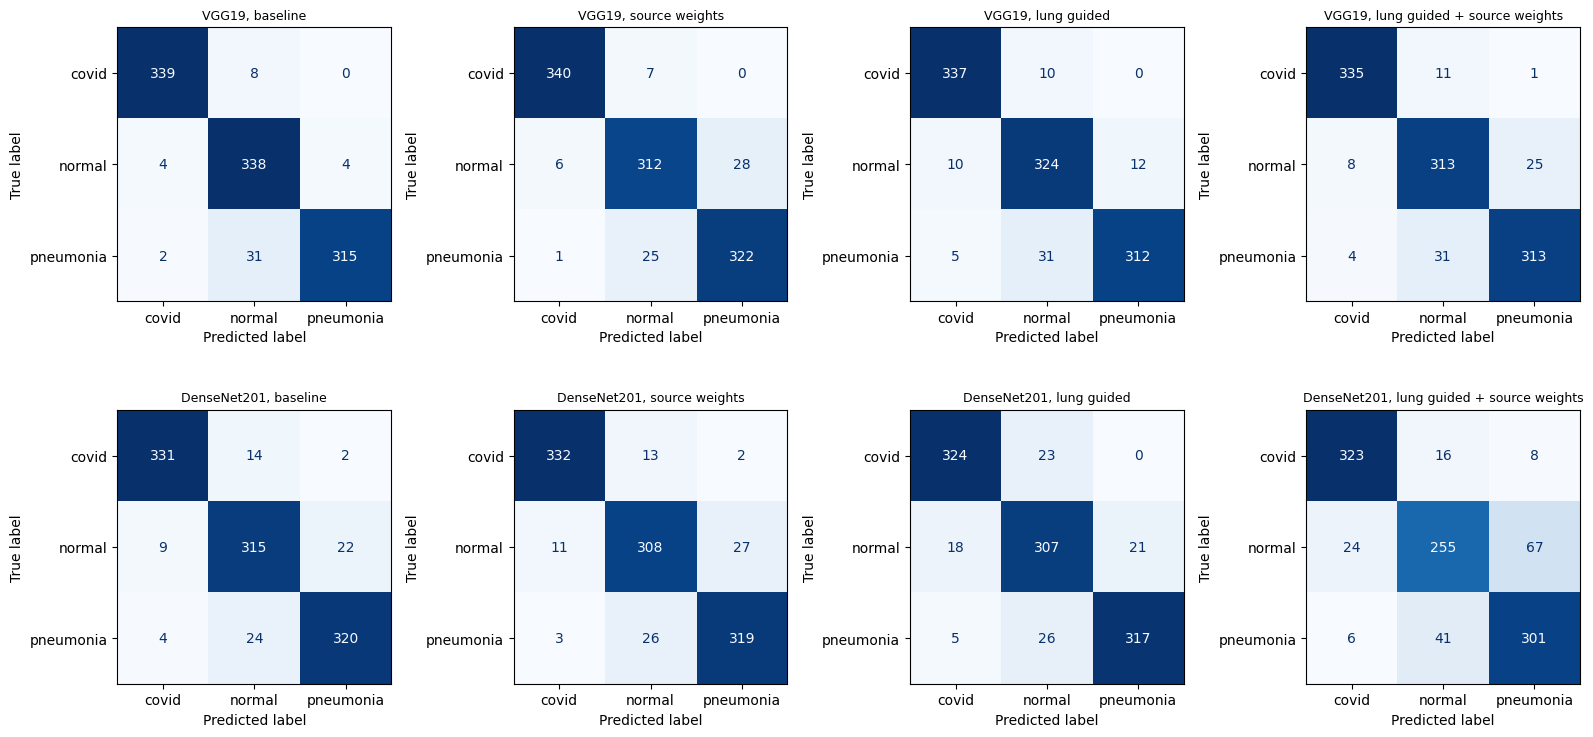

In [ ]:
# Confusion matrices on the unseen set, seeds averaged.
show_models = ["baseline", "source weights", "lung guided", "lung guided + source weights"]
fig, axes = plt.subplots(len(CONFIG["backbones"]), len(show_models), figsize=(4.0 * len(show_models), 3.9 * len(CONFIG["backbones"])))
axes = np.atleast_2d(axes)
for r, name in enumerate(CONFIG["backbones"]):
    for c, model_name in enumerate(show_models):
        evaluate.confusion_from_probs(y_u, seed_average(name, model_name), CLASSES, f"{name}, {model_name}", axes[r, c])
plt.tight_layout()
plt.show()

## 10. Summary

In [ ]:
cols = ["accuracy", "pneumonia recall, PNG", "normal recall, JPEG", "normal vs pneumonia AUC, PNG", "Grad CAM heat inside lungs"]
parts = []
for name in CONFIG["backbones"]:
    t = results_table("unseen", name)[cols].copy()
    t.insert(0, "network", name)
    parts.append(t)
summary = pd.concat(parts)
display(summary)
print(f"Lungs cover {LUNG_AREA:.0%} of the picture, so heat inside the lungs above that share means the model prefers the lungs.")
print("Chosen penalty strength:", CHOSEN_LAMBDA)
print(f"Total run time: {(time.time() - RUN_START) / 60:.0f} minutes.")

,network,accuracy,"pneumonia recall, PNG","normal recall, JPEG","normal vs pneumonia AUC, PNG",Grad CAM heat inside lungs
Week 10 classifier,VGG19,93.9 ± 0.5,1.2 ± 2.1,82.7 ± 6.1,0.672 ± 0.039,nan ± nan
lungs only input (parent paper 2),VGG19,89.8 ± 0.6,7.4 ± 3.7,60.0 ± 17.3,0.666 ± 0.021,40.3 ± 1.4
baseline,VGG19,94.4 ± 1.1,9.9 ± 7.7,89.3 ± 10.1,0.656 ± 0.032,23.3 ± 0.1
source weights,VGG19,92.6 ± 0.8,24.7 ± 5.7,90.7 ± 6.4,0.646 ± 0.028,23.1 ± 0.4
lung guided,VGG19,93.1 ± 0.2,4.9 ± 2.1,88.0 ± 6.0,0.586 ± 0.040,56.2 ± 3.2
lung guided + source weights,VGG19,92.0 ± 1.0,19.8 ± 15.0,92.7 ± 8.1,0.644 ± 0.048,45.1 ± 2.4
Week 10 classifier,DenseNet201,93.3 ± 0.1,8.6 ± 11.9,93.3 ± 3.1,0.697 ± 0.008,nan ± nan
lungs only input (parent paper 2),DenseNet201,88.3 ± 0.7,8.6 ± 7.7,65.3 ± 19.6,0.629 ± 0.012,35.6 ± 0.7
baseline,DenseNet201,93.0 ± 0.4,24.7 ± 2.1,88.7 ± 3.1,0.696 ± 0.015,27.5 ± 0.1
source weights,DenseNet201,92.0 ± 0.9,29.6 ± 9.8,93.3 ± 3.1,0.693 ± 0.011,27.5 ± 0.1


Lungs cover 23% of the picture, so heat inside the lungs above that share means the model prefers the lungs.
Chosen penalty strength: {'VGG19': 0.5, 'DenseNet201': 5.0}
Total run time: 42 minutes.
